In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/abankitabehera/pcb-defects/test/images/01_missing_hole_02_jpg.rf.653e7a3d3352f695622f788241c5626d.jpg
/kaggle/input/datasets/abankitabehera/pcb-defects/test/images/01_missing_hole_08_jpg.rf.5abfc2d0f03dee9b824089676e6f8151.jpg
/kaggle/input/datasets/abankitabehera/pcb-defects/test/images/01_missing_hole_09_jpg.rf.d7693f7fca88d8acaabdc4a5ac14ab72.jpg
/kaggle/input/datasets/abankitabehera/pcb-defects/test/images/01_missing_hole_10_jpg.rf.7c4604ead4d9b8e597b5fe071beba025.jpg
/kaggle/input/datasets/abankitabehera/pcb-defects/test/images/01_missing_hole_15_jpg.rf.155026c2b1585f59c29d4547205e76d2.jpg
/kaggle/input/datasets/abankitabehera/pcb-defects/test/images/01_missing_hole_19_jpg.rf.76601bcc37c62f8723c2e39f4d59edad.jpg
/kaggle/input/datasets/abankitabehera/pcb-defects/test/images/01_mouse_bite_02_jpg.rf.c4be20393490e5cd8299ef8c7270f131.jpg
/kaggle/input/datasets/abankitabehera/pcb-defects/test/images/01_mouse_bite_06_jpg.rf.2ac048cfb916c9082728b25682794843.jpg
/kag

In [2]:
import subprocess
import sys

# System-wide install helps DDP child processes import Ultralytics.
subprocess.run(
    ["pip", "install", "-q", "-U", "ultralytics", "PyYAML"],
    check=True
)

print("Python executable:", sys.executable)
print("Ultralytics installation completed.")

Python executable: /usr/bin/python3
Ultralytics installation completed.


In [3]:
from pathlib import Path
import subprocess
import sys

try:
    import kagglehub
except ImportError:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "kagglehub"],
        check=True
    )
    import kagglehub

DATASET_HANDLE = "abankitabehera/pcb-defects"

print("Downloading:", DATASET_HANDLE)

try:
    downloaded_path = kagglehub.dataset_download(DATASET_HANDLE)
    DATASET_PATH = Path(downloaded_path)

    if not DATASET_PATH.exists():
        raise FileNotFoundError(downloaded_path)

    print("\nDataset successfully attached/downloaded.")
    print("Dataset path:", DATASET_PATH)

except Exception as e:
    print("\nKaggleHub download failed:", repr(e))
    print(
        "\nAlternative: Open the Kaggle Notebook Input panel, "
        "click Add Input, search for abankitabehera/pcb-defects, "
        "and attach the dataset."
    )
    raise

Downloading: abankitabehera/pcb-defects

Dataset successfully attached/downloaded.
Dataset path: /kaggle/input/datasets/abankitabehera/pcb-defects


In [4]:
from collections import Counter
from pathlib import Path

extensions = Counter()

for p in DATASET_PATH.rglob("*"):
    if p.is_file():
        extensions[p.suffix.lower()] += 1

print("DATASET CONTENT SUMMARY")
print("=======================")

for ext, count in extensions.most_common():
    print(f"{ext or '[no extension]':15s}: {count}")

print("\nTOP-LEVEL CONTENT")

for p in sorted(DATASET_PATH.iterdir()):
    print(
        "[DIR] " if p.is_dir() else "[FILE]",
        p.name
    )

print("\nANNOTATION FILES")

for ext in [".yaml", ".yml", ".json", ".xml", ".txt"]:
    files = list(DATASET_PATH.rglob(f"*{ext}"))

    print(f"\n{ext}: {len(files)} files")

    for p in files[:10]:
        print(" ", p.relative_to(DATASET_PATH))

print("\nIMAGE FILES")

image_extensions = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".tif", ".tiff", ".webp"
}

images = [
    p for p in DATASET_PATH.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

print("Total images:", len(images))

for p in images[:15]:
    print(" ", p.relative_to(DATASET_PATH))

DATASET CONTENT SUMMARY
.jpg           : 2586
.txt           : 2586

TOP-LEVEL CONTENT
[DIR]  test
[DIR]  train
[DIR]  valid

ANNOTATION FILES

.yaml: 0 files

.yml: 0 files

.json: 0 files

.xml: 0 files

.txt: 2586 files
  valid/labels/01_missing_hole_02_jpg.rf.c800f8755167bcd15eb9396f7a084ad8.txt
  valid/labels/01_missing_hole_03_jpg.rf.f866c94f6cca956f72671c90540efc07.txt
  valid/labels/01_missing_hole_04_jpg.rf.8ccf7c95b051e3ab9ceed3ce6d98799b.txt
  valid/labels/01_missing_hole_06_jpg.rf.324108f7dfc7a1a24d5c8200db8856a2.txt
  valid/labels/01_missing_hole_07_jpg.rf.337d9d3fa36a374810becb36a65a853e.txt
  valid/labels/01_missing_hole_08_jpg.rf.dc97da00618c20277d44b4b2866a7a94.txt
  valid/labels/01_missing_hole_09_jpg.rf.e0a55b4132ea0faaafe8dcc19c5669b1.txt
  valid/labels/01_missing_hole_10_jpg.rf.d4f5b1563a49a0e101acea8b8a8b2e41.txt
  valid/labels/01_missing_hole_11_jpg.rf.6a071069d8b2c9633ce30c8981cc8331.txt
  valid/labels/01_missing_hole_12_jpg.rf.59720b81d615e9508b3a3d6f94d1c3b5.t

In [5]:
from pathlib import Path

SEARCH_DIRS = [
    Path("/kaggle/input"),
    Path("/kaggle/working/pcb_extracted")
]

for base in SEARCH_DIRS:

    if not base.exists():
        continue

    print(f"\nSearching: {base}")

    for p in base.rglob("*"):
        if p.is_dir() and p.name.lower() in {
            "train", "valid", "val", "test",
            "images", "labels"
        }:
            print("[DIR]", p)

        elif p.is_file() and p.name.lower() == "data.yaml":
            print("[YAML]", p)


Searching: /kaggle/input
[DIR] /kaggle/input/datasets/abankitabehera/pcb-defects/test
[DIR] /kaggle/input/datasets/abankitabehera/pcb-defects/train
[DIR] /kaggle/input/datasets/abankitabehera/pcb-defects/valid
[DIR] /kaggle/input/datasets/abankitabehera/pcb-defects/test/images
[DIR] /kaggle/input/datasets/abankitabehera/pcb-defects/test/labels
[DIR] /kaggle/input/datasets/abankitabehera/pcb-defects/train/images
[DIR] /kaggle/input/datasets/abankitabehera/pcb-defects/train/labels
[DIR] /kaggle/input/datasets/abankitabehera/pcb-defects/valid/images
[DIR] /kaggle/input/datasets/abankitabehera/pcb-defects/valid/labels


In [6]:

# CELL 6 — PCB DATASET SETUP, ANNOTATION CHECK AND YAML CREATION

from pathlib import Path
from collections import Counter
from tqdm.auto import tqdm
from PIL import Image
import numpy as np
import yaml

# --------------------------------------------------
# 1. Direct dataset path
# --------------------------------------------------

DATA_ROOT = Path(
    "/kaggle/input/datasets/abankitabehera/pcb-defects"
)

assert DATA_ROOT.exists(), (
    f"Dataset not found: {DATA_ROOT}"
)

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".tif", ".tiff", ".webp"
}

CLASS_NAMES = [
    "missing_hole",
    "mouse_bite",
    "open_circuit",
    "short",
    "spur",
    "spurious_copper"
]

# These paths match the actual Kaggle dataset structure.
SPLITS = {
    split: {
        "images": DATA_ROOT / split / "images",
        "labels": DATA_ROOT / split / "labels"
    }
    for split in ["train", "valid", "test"]
}

print("DATASET:", DATA_ROOT)
print("=" * 60)

# --------------------------------------------------
# 2. Verify all directories
# --------------------------------------------------

for split, paths in SPLITS.items():

    for key, folder in paths.items():

        if not folder.is_dir():
            raise FileNotFoundError(
                f"Missing directory: {folder}"
            )

        print(f"{split}/{key}: {folder}")

# --------------------------------------------------
# 3. Image listing helper
# --------------------------------------------------

def image_files(folder):

    return sorted(
        p for p in folder.rglob("*")
        if p.is_file()
        and p.suffix.lower() in IMAGE_EXTENSIONS
    )


# --------------------------------------------------
# 4. Check images and matching YOLO annotations
# --------------------------------------------------

AUDIT_SUMMARY = {}
TOTAL_IMAGES = 0
TOTAL_BOXES = 0

TEST_HAS_LABELS = False

for split, paths in SPLITS.items():

    img_dir = paths["images"]
    label_dir = paths["labels"]

    images = image_files(img_dir)
    label_paths = list(label_dir.glob("*.txt"))

    label_map = {
        p.stem: p for p in label_paths
    }

    missing_labels = []
    corrupt_images = []
    invalid_labels = []
    class_counts = Counter()
    image_class_counts = Counter()
    dimensions = Counter()

    empty_labels = 0
    boxes_checked = 0

    print(f"\nChecking {split.upper()} dataset...")
    print("Images:", len(images))
    print("Label files:", len(label_paths))

    # Progress bar for all images in this split.
    for img_path in tqdm(
        images,
        desc=f"Auditing {split}",
        unit="image",
        dynamic_ncols=True
    ):

        label_path = label_map.get(img_path.stem)

        # Check image integrity and image dimensions.
        try:
            with Image.open(img_path) as im:

                width, height = im.size
                im.verify()

            dimensions[(width, height)] += 1

        except Exception as e:

            corrupt_images.append(
                (img_path.name, str(e))
            )
            continue

        # Matching label file.
        if label_path is None:

            missing_labels.append(img_path.name)
            continue

        lines = label_path.read_text().splitlines()

        if not any(line.strip() for line in lines):
            empty_labels += 1

        present_classes = set()

        for line_number, line in enumerate(lines, 1):

            if not line.strip():
                continue

            try:

                values = [
                    float(x) for x in line.split()
                ]

                if len(values) != 5:
                    raise ValueError(
                        "Expected 5 YOLO annotation values"
                    )

                class_float, xc, yc, bw, bh = values

                if not np.isfinite(values).all():
                    raise ValueError("Non-finite annotation")

                class_id = int(class_float)

                if class_float != class_id:
                    raise ValueError("Class ID must be an integer")

                if not 0 <= class_id < 6:
                    raise ValueError(
                        f"Invalid class ID: {class_id}"
                    )

                if not (
                    0 <= xc <= 1
                    and 0 <= yc <= 1
                    and 0 < bw <= 1
                    and 0 < bh <= 1
                ):
                    raise ValueError(
                        "Invalid normalised bounding box"
                    )

                # Ensure the box is inside the image.
                if (
                    xc - bw / 2 < -0.001
                    or yc - bh / 2 < -0.001
                    or xc + bw / 2 > 1.001
                    or yc + bh / 2 > 1.001
                ):
                    raise ValueError(
                        "Bounding box exceeds image boundaries"
                    )

                class_counts[class_id] += 1
                present_classes.add(class_id)
                boxes_checked += 1

            except Exception as e:

                invalid_labels.append(
                    (
                        label_path.name,
                        line_number,
                        str(e)
                    )
                )

        for class_id in present_classes:
            image_class_counts[class_id] += 1

        TOTAL_IMAGES += 1

    # Check for annotation files without a corresponding image.
    image_stems = {
        p.stem for p in images
    }

    orphan_labels = [
        p.name for p in label_paths
        if p.stem not in image_stems
    ]

    TOTAL_BOXES += boxes_checked

    AUDIT_SUMMARY[split] = {
        "images": len(images),
        "labels": len(label_paths),
        "boxes": boxes_checked,
        "missing_labels": len(missing_labels),
        "empty_labels": empty_labels,
        "invalid_labels": len(invalid_labels),
        "corrupt_images": len(corrupt_images),
        "orphan_labels": len(orphan_labels),
        "class_counts": class_counts,
        "image_class_counts": image_class_counts,
        "dimensions": dimensions
    }

    print(f"\n{split.upper()} RESULTS")
    print("-" * 40)

    print("Images:", len(images))
    print("Boxes:", boxes_checked)
    print("Missing labels:", len(missing_labels))
    print("Empty labels:", empty_labels)
    print("Invalid labels:", len(invalid_labels))
    print("Corrupt images:", len(corrupt_images))
    print("Orphan labels:", len(orphan_labels))

    print("Image dimensions:", dimensions)

    if missing_labels:
        print("Missing examples:", missing_labels[:5])

    if invalid_labels:
        print("Invalid examples:", invalid_labels[:5])

    if corrupt_images:
        print("Corrupt examples:", corrupt_images[:5])

    if orphan_labels:
        print("Orphan examples:", orphan_labels[:5])

    if missing_labels or invalid_labels or corrupt_images or orphan_labels:
        raise RuntimeError(
            f"Dataset integrity problems found in {split}. "
            "Stop and investigate before training."
        )

# --------------------------------------------------
# 5. Confirm test annotations
# --------------------------------------------------

TEST_HAS_LABELS = (
    AUDIT_SUMMARY["test"]["images"] > 0
    and AUDIT_SUMMARY["test"]["images"]
    == AUDIT_SUMMARY["test"]["labels"]
)

# --------------------------------------------------
# 6. Create the working data.yaml
# --------------------------------------------------

DATA_CONFIG = {
    "path": str(DATA_ROOT),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 6,
    "names": CLASS_NAMES
}

DATA_YAML = Path(
    "/kaggle/working/pcb_data.yaml"
)

DATA_YAML.write_text(
    yaml.safe_dump(
        DATA_CONFIG,
        sort_keys=False
    )
)

# --------------------------------------------------
# 7. Final report
# --------------------------------------------------

print("\n" + "=" * 60)
print("DATASET VERIFICATION COMPLETED")
print("=" * 60)

print("Total images checked:", TOTAL_IMAGES)
print("Total bounding boxes:", TOTAL_BOXES)

for split in ["train", "valid", "test"]:

    print(
        f"{split}: "
        f"{AUDIT_SUMMARY[split]['images']} images, "
        f"{AUDIT_SUMMARY[split]['boxes']} boxes"
    )

print("\nClass mapping:")

for i, name in enumerate(CLASS_NAMES):
    print(i, ":", name)

print("\nWorking YAML created:", DATA_YAML)
print(DATA_YAML.read_text())

print("\nTest labels available:", TEST_HAS_LABELS)

print("\nDataset is ready for subsequent audit and training cells.")


DATASET: /kaggle/input/datasets/abankitabehera/pcb-defects
train/images: /kaggle/input/datasets/abankitabehera/pcb-defects/train/images
train/labels: /kaggle/input/datasets/abankitabehera/pcb-defects/train/labels
valid/images: /kaggle/input/datasets/abankitabehera/pcb-defects/valid/images
valid/labels: /kaggle/input/datasets/abankitabehera/pcb-defects/valid/labels
test/images: /kaggle/input/datasets/abankitabehera/pcb-defects/test/images
test/labels: /kaggle/input/datasets/abankitabehera/pcb-defects/test/labels

Checking TRAIN dataset...
Images: 1880
Label files: 1880


Auditing train:   0%|          | 0/1880 [00:00<?, ?image/s]


TRAIN RESULTS
----------------------------------------
Images: 1880
Boxes: 7974
Missing labels: 0
Empty labels: 0
Invalid labels: 0
Corrupt images: 0
Orphan labels: 0
Image dimensions: Counter({(640, 640): 1325, (3056, 2464): 103, (3034, 1586): 96, (2775, 2159): 51, (2529, 2530): 50, (2544, 2156): 49, (2759, 2154): 49, (2282, 2248): 49, (2868, 2316): 44, (2904, 1921): 43, (2240, 2016): 21})

Checking VALID dataset...
Images: 517
Label files: 517


Auditing valid:   0%|          | 0/517 [00:00<?, ?image/s]


VALID RESULTS
----------------------------------------
Images: 517
Boxes: 2218
Missing labels: 0
Empty labels: 0
Invalid labels: 0
Corrupt images: 0
Orphan labels: 0
Image dimensions: Counter({(640, 640): 379, (3034, 1586): 24, (3056, 2464): 17, (2868, 2316): 17, (2904, 1921): 17, (2544, 2156): 11, (2759, 2154): 11, (2240, 2016): 11, (2282, 2248): 11, (2529, 2530): 10, (2775, 2159): 9})

Checking TEST dataset...
Images: 189
Label files: 189


Auditing test:   0%|          | 0/189 [00:00<?, ?image/s]


TEST RESULTS
----------------------------------------
Images: 189
Boxes: 820
Missing labels: 0
Empty labels: 0
Invalid labels: 0
Corrupt images: 0
Orphan labels: 0
Image dimensions: Counter({(640, 640): 189})

DATASET VERIFICATION COMPLETED
Total images checked: 2586
Total bounding boxes: 11012
train: 1880 images, 7974 boxes
valid: 517 images, 2218 boxes
test: 189 images, 820 boxes

Class mapping:
0 : missing_hole
1 : mouse_bite
2 : open_circuit
3 : short
4 : spur
5 : spurious_copper

Working YAML created: /kaggle/working/pcb_data.yaml
path: /kaggle/input/datasets/abankitabehera/pcb-defects
train: train/images
val: valid/images
test: test/images
nc: 6
names:
- missing_hole
- mouse_bite
- open_circuit
- short
- spur
- spurious_copper


Test labels available: True

Dataset is ready for subsequent audit and training cells.


TRAINING CLASS DISTRIBUTION


,Class ID,Class,Bounding Boxes,Images
0,0,missing_hole,1160,272
1,1,mouse_bite,1302,308
2,2,open_circuit,1341,319
3,3,short,1389,326
4,4,spur,1423,338
5,5,spurious_copper,1359,317



Maximum / minimum class ratio: 1.23
Selected class weighting (cls_pw): 0.0


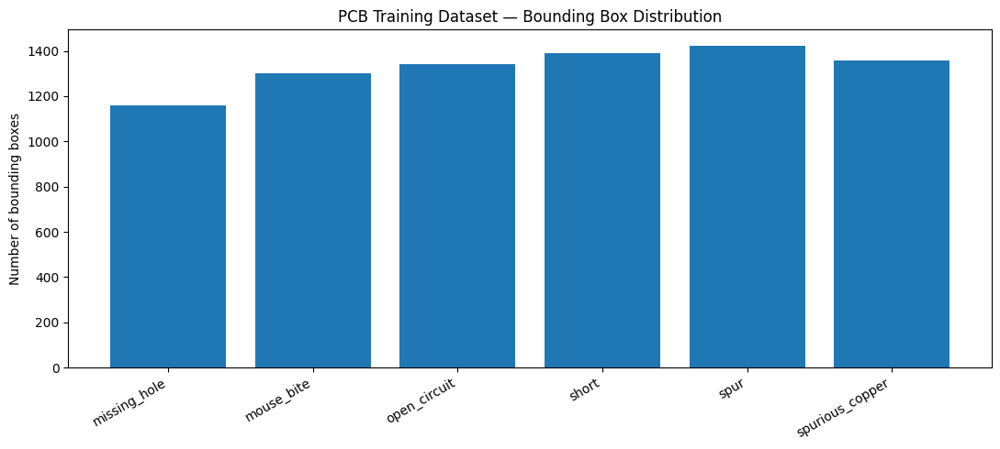

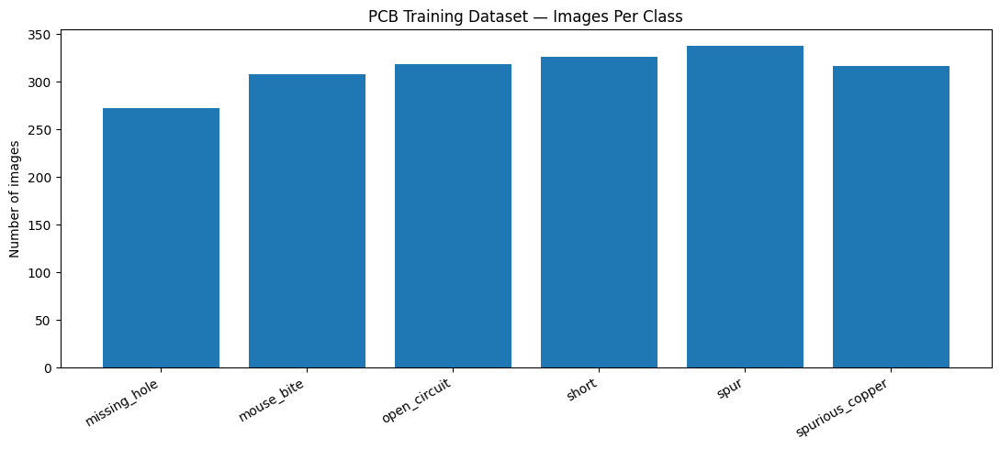

In [7]:
# CELL 7 — CLASS DISTRIBUTION AND IMBALANCE

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

assert "AUDIT_SUMMARY" in globals()
assert "CLASS_NAMES" in globals()

class_data = []

for i, name in enumerate(CLASS_NAMES):

    class_data.append({
        "Class ID": i,
        "Class": name,
        "Bounding Boxes": AUDIT_SUMMARY["train"]["class_counts"][i],
        "Images": AUDIT_SUMMARY["train"]["image_class_counts"][i]
    })

class_df = pd.DataFrame(class_data)

print("TRAINING CLASS DISTRIBUTION")
display(class_df)

counts = class_df["Bounding Boxes"].to_numpy(dtype=float)

if np.any(counts == 0):
    raise RuntimeError("At least one class has zero training annotations.")

imbalance_ratio = counts.max() / counts.min()

if imbalance_ratio < 2:
    CLS_PW = 0.0
elif imbalance_ratio < 5:
    CLS_PW = 0.25
else:
    CLS_PW = 0.5

print("\nMaximum / minimum class ratio:", round(imbalance_ratio, 2))
print("Selected class weighting (cls_pw):", CLS_PW)

# Plot bounding box distribution
plt.figure(figsize=(11, 5))
plt.bar(
    class_df["Class"],
    class_df["Bounding Boxes"]
)
plt.title("PCB Training Dataset — Bounding Box Distribution")
plt.ylabel("Number of bounding boxes")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# Plot image distribution
plt.figure(figsize=(11, 5))
plt.bar(
    class_df["Class"],
    class_df["Images"]
)
plt.title("PCB Training Dataset — Images Per Class")
plt.ylabel("Number of images")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [8]:

# CELL 8 — FINAL CLASS ID VERIFICATION
# Resolves spur vs spurious_copper substring overlap.

from collections import defaultdict, Counter
from tqdm.auto import tqdm
import pandas as pd
import re

def normalise_name(value):
    return re.sub(r"[^a-z0-9]", "", str(value).lower())

normalised_classes = [
    normalise_name(name) for name in CLASS_NAMES
]

mapping_counts = defaultdict(Counter)
unmatched_images = []
ambiguous_images = []
missing_label_images = []

for split in ["train", "valid", "test"]:

    print(f"\nChecking {split.upper()}")

    images = image_files(SPLITS[split]["images"])

    for image_path in tqdm(
        images,
        desc=f"Mapping {split}",
        unit="image"
    ):

        stem = normalise_name(image_path.stem)

        matches = [
            (len(class_name), class_id)
            for class_id, class_name in enumerate(normalised_classes)
            if class_name in stem
        ]

        if not matches:
            unmatched_images.append(
                (split, image_path.name)
            )
            continue

        # Select the longest matching class name.
        longest_length = max(length for length, _ in matches)

        best_matches = [
            class_id for length, class_id in matches
            if length == longest_length
        ]

        if len(best_matches) != 1:
            ambiguous_images.append(
                (split, image_path.name, best_matches)
            )
            continue

        filename_class_id = best_matches[0]

        label_path = (
            SPLITS[split]["labels"] /
            f"{image_path.stem}.txt"
        )

        if not label_path.exists():
            missing_label_images.append(
                (split, image_path.name)
            )
            continue

        for line in label_path.read_text().splitlines():

            if not line.strip():
                continue

            annotation_class_id = int(
                float(line.split()[0])
            )

            if not 0 <= annotation_class_id < 6:
                raise ValueError(
                    f"Invalid annotation ID: {annotation_class_id}"
                )

            mapping_counts[filename_class_id][
                annotation_class_id
            ] += 1


# Build complete mapping matrix.
rows = []

for filename_id, filename_class in enumerate(CLASS_NAMES):

    row = {
        "Filename class": filename_class
    }

    total = sum(mapping_counts[filename_id].values())
    correct = mapping_counts[filename_id][filename_id]

    for annotation_id, annotation_name in enumerate(CLASS_NAMES):
        row[annotation_name] = mapping_counts[filename_id][annotation_id]

    row["Total boxes"] = total
    row["Agreement %"] = (
        round(100 * correct / total, 2)
        if total else 0
    )

    rows.append(row)

mapping_df = pd.DataFrame(rows)

print("\nFINAL CLASS MAPPING MATRIX")
display(mapping_df)

# Calculate global agreement.
total_boxes = sum(
    sum(mapping_counts[i].values())
    for i in range(6)
)

correct_boxes = sum(
    mapping_counts[i][i]
    for i in range(6)
)

agreement = (
    100 * correct_boxes / total_boxes
    if total_boxes else 0
)

print("\nGLOBAL RESULTS")
print("Total mapped boxes:", total_boxes)
print("Matching boxes:", correct_boxes)
print("Overall agreement:", round(agreement, 2), "%")
print("Unmatched images:", len(unmatched_images))
print("Ambiguous images:", len(ambiguous_images))
print("Missing label images:", len(missing_label_images))

print("\nUnmatched examples:", unmatched_images[:5])
print("Ambiguous examples:", ambiguous_images[:5])

# Final decision.
MAPPING_VERIFIED = (
    total_boxes > 0
    and agreement == 100.0
    and len(unmatched_images) == 0
    and len(ambiguous_images) == 0
    and len(missing_label_images) == 0
    and all(
        mapping_counts[i][i] > 0
        for i in range(6)
    )
)

print("\nCLASS MAPPING VERIFIED:", MAPPING_VERIFIED)

if not MAPPING_VERIFIED:
    print("STOP: Investigate the class mapping before training.")
else:
    print("All six classes have matching filename and annotation IDs.")



Checking TRAIN


Mapping train:   0%|          | 0/1880 [00:00<?, ?image/s]


Checking VALID


Mapping valid:   0%|          | 0/517 [00:00<?, ?image/s]


Checking TEST


Mapping test:   0%|          | 0/189 [00:00<?, ?image/s]


FINAL CLASS MAPPING MATRIX


,Filename class,missing_hole,mouse_bite,open_circuit,short,spur,spurious_copper,Total boxes,Agreement %
0,missing_hole,1723,0,0,0,0,0,1723,100.0
1,mouse_bite,0,1770,0,0,0,0,1770,100.0
2,open_circuit,0,0,1833,0,0,0,1833,100.0
3,short,0,0,0,1882,0,0,1882,100.0
4,spur,0,0,0,0,1888,0,1888,100.0
5,spurious_copper,0,0,0,0,0,1916,1916,100.0



GLOBAL RESULTS
Total mapped boxes: 11012
Matching boxes: 11012
Overall agreement: 100.0 %
Unmatched images: 0
Ambiguous images: 0
Missing label images: 0

Unmatched examples: []
Ambiguous examples: []

CLASS MAPPING VERIFIED: True
All six classes have matching filename and annotation IDs.


Analysing defect sizes:   0%|          | 0/1880 [00:00<?, ?it/s]

Bounding box statistics:


,width,height,area
count,7974.000000,7974.000000,7974.000000
mean,35.944375,35.212417,1775.685150
std,28.052232,25.312171,2547.181487
min,4.686000,2.145000,51.901820
25%,17.605000,17.978250,335.973900
50%,24.446500,24.793000,564.339864
75%,46.000000,46.471250,2495.500000
max,283.000000,215.000000,37268.000000



Small defect percentages:
Boxes narrower than 8px: 0.55%
Boxes narrower than 16px: 17.24%
Boxes narrower than 32px: 64.26%
Boxes narrower than 64px: 84.91%


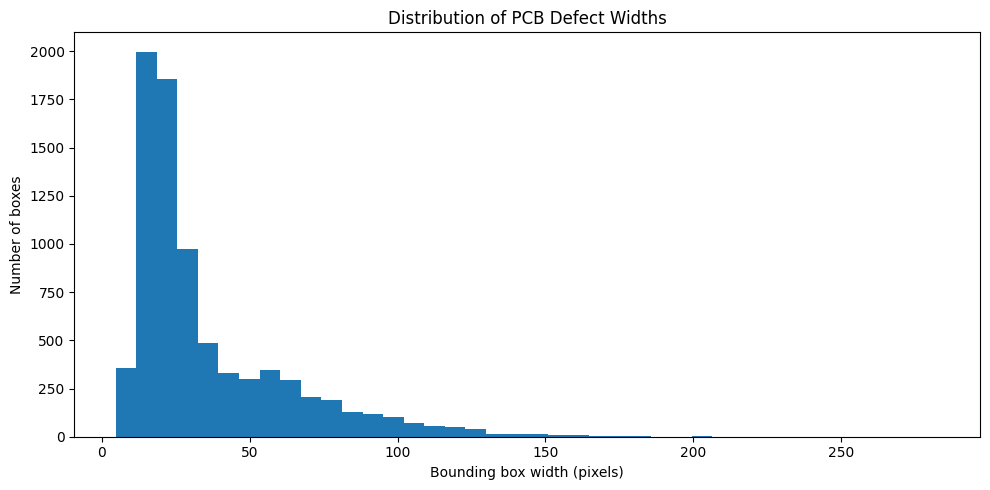

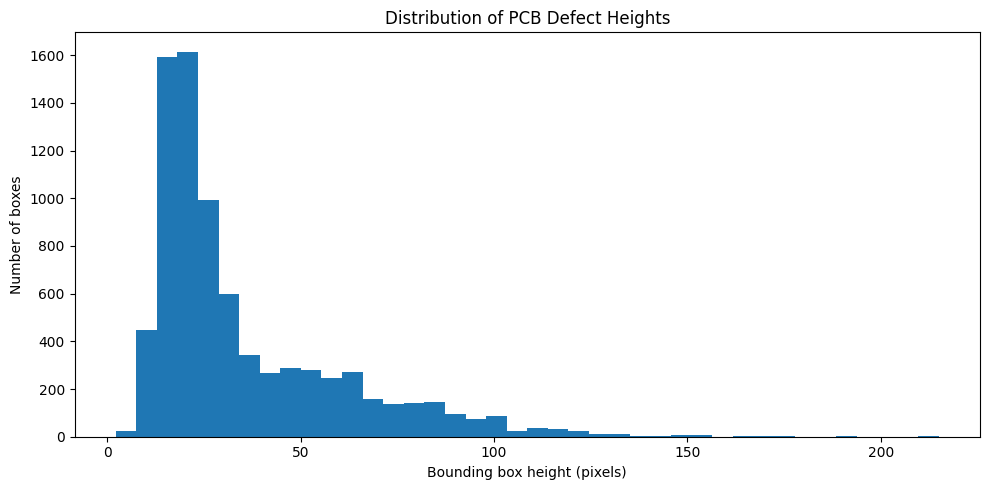

In [9]:
# CELL 9 — BOUNDING BOX SIZE ANALYSIS

from tqdm.auto import tqdm
from PIL import Image

box_records = []

train_images = image_files(SPLITS["train"]["images"])

for image_path in tqdm(
    train_images,
    desc="Analysing defect sizes"
):

    label_path = (
        SPLITS["train"]["labels"] /
        f"{image_path.stem}.txt"
    )

    with Image.open(image_path) as im:
        width, height = im.size

    for line in label_path.read_text().splitlines():

        if not line.strip():
            continue

        cls, xc, yc, bw, bh = map(float, line.split())

        pixel_width = bw * width
        pixel_height = bh * height
        area = pixel_width * pixel_height

        box_records.append({
            "class": CLASS_NAMES[int(cls)],
            "width": pixel_width,
            "height": pixel_height,
            "area": area,
            "area_percentage": 100 * area / (width * height)
        })

box_df = pd.DataFrame(box_records)

print("Bounding box statistics:")
display(box_df[["width", "height", "area"]].describe())

print("\nSmall defect percentages:")

for threshold in [8, 16, 32, 64]:

    percentage = (
        (box_df["width"] < threshold).mean() * 100
    )

    print(
        f"Boxes narrower than {threshold}px:",
        f"{percentage:.2f}%"
    )

plt.figure(figsize=(10, 5))
plt.hist(box_df["width"], bins=40)
plt.xlabel("Bounding box width (pixels)")
plt.ylabel("Number of boxes")
plt.title("Distribution of PCB Defect Widths")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.hist(box_df["height"], bins=40)
plt.xlabel("Bounding box height (pixels)")
plt.ylabel("Number of boxes")
plt.title("Distribution of PCB Defect Heights")
plt.tight_layout()
plt.show()

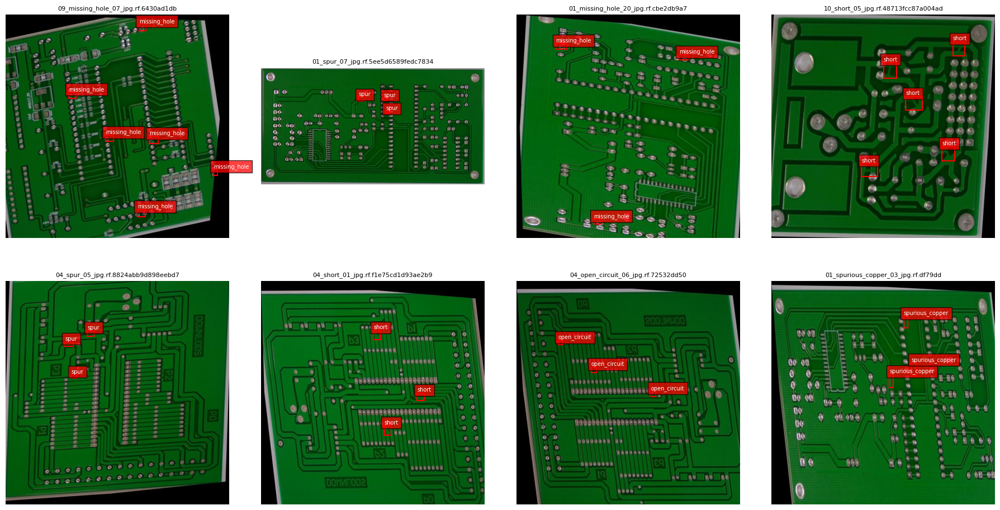

In [10]:
# CELL 10 — VISUAL ANNOTATION INSPECTION

import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

random.seed(42)

samples = random.sample(
    train_images,
    min(8, len(train_images))
)

fig, axes = plt.subplots(2, 4, figsize=(18, 10))
axes = axes.flatten()

for ax, image_path in zip(axes, samples):

    with Image.open(image_path) as im:
        image = im.convert("RGB")
        W, H = image.size

    ax.imshow(image)
    ax.set_title(image_path.name[:35], fontsize=8)
    ax.axis("off")

    label_path = (
        SPLITS["train"]["labels"] /
        f"{image_path.stem}.txt"
    )

    for line in label_path.read_text().splitlines():

        if not line.strip():
            continue

        cls, xc, yc, bw, bh = map(float, line.split())

        x1 = (xc - bw / 2) * W
        y1 = (yc - bh / 2) * H

        rect = patches.Rectangle(
            (x1, y1),
            bw * W,
            bh * H,
            edgecolor="red",
            facecolor="none",
            linewidth=1.5
        )

        ax.add_patch(rect)

        ax.text(
            x1,
            max(0, y1 - 4),
            CLASS_NAMES[int(cls)],
            color="white",
            fontsize=7,
            bbox=dict(facecolor="red", alpha=0.75)
        )

for ax in axes[len(samples):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [11]:
# CELL 11 — FINAL DATASET PATH VERIFICATION

import yaml
from pathlib import Path

cfg = yaml.safe_load(DATA_YAML.read_text())

print("Working YAML:")
print(DATA_YAML.read_text())

assert cfg["nc"] == 6
assert cfg["names"] == CLASS_NAMES

for split, key in [
    ("train", "train"),
    ("valid", "val"),
    ("test", "test")
]:

    image_dir = Path(cfg["path"]) / cfg[key]
    label_dir = SPLITS[split]["labels"]

    assert image_dir.exists(), f"Missing images: {image_dir}"
    assert label_dir.exists(), f"Missing labels: {label_dir}"

    images = image_files(image_dir)
    labels = list(label_dir.glob("*.txt"))

    print(
        f"{split.upper()}: "
        f"{len(images)} images | {len(labels)} labels"
    )

    assert len(images) == len(labels), (
        f"Image/label count mismatch in {split}"
    )

print("\nDATASET READY FOR YOLO26m")

Working YAML:
path: /kaggle/input/datasets/abankitabehera/pcb-defects
train: train/images
val: valid/images
test: test/images
nc: 6
names:
- missing_hole
- mouse_bite
- open_circuit
- short
- spur
- spurious_copper

TRAIN: 1880 images | 1880 labels
VALID: 517 images | 517 labels
TEST: 189 images | 189 labels

DATASET READY FOR YOLO26m


In [12]:
# CELL 12 — GPU AND DDP ENVIRONMENT CHECK

import torch
import sys
import subprocess
import ultralytics

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("CUDA:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

if not torch.cuda.is_available():
    raise RuntimeError("CUDA is not available.")

if torch.cuda.device_count() != 2:
    raise RuntimeError(
        "Expected exactly two visible GPUs. "
        "Select GPU T4 x2 in Kaggle settings."
    )

for i in range(2):

    print(
        f"GPU {i}:",
        torch.cuda.get_device_name(i)
    )

    print(
        "VRAM:",
        round(
            torch.cuda.get_device_properties(i).total_memory
            / 1024**3,
            2
        ),
        "GB"
    )

# Verify that a spawned DDP Python process can import dependencies.
probe_code = """
import torch
import ultralytics
print('Child Python can import PyTorch and Ultralytics')
print('Ultralytics:', ultralytics.__version__)
"""

probe = subprocess.run(
    [sys.executable, "-c", probe_code],
    capture_output=True,
    text=True
)

print("\nDDP subprocess check:")
print(probe.stdout)

if probe.returncode != 0:
    print(probe.stderr)
    raise RuntimeError(
        "DDP subprocess import check failed. "
        "Resolve this before training."
    )

print("Both GPUs and DDP Python environment verified.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Python: /usr/bin/python3
PyTorch: 2.11.0+cu130
Ultralytics: 8.4.210
CUDA: True
GPU count: 2
GPU 0: Tesla T4
VRAM: 14.56 GB
GPU 1: Tesla T4
VRAM: 14.56 GB

DDP subprocess check:
Child Python can import PyTorch and Ultralytics
Ultralytics: 8.4.210

Both GPUs and DDP Python environment verified.


In [13]:
# CELL 13 — LOAD PRETRAINED YOLO26m

from ultralytics import YOLO
from pathlib import Path

MODEL_NAME = "yolo26m.pt"

print("Loading pretrained model:", MODEL_NAME)

model = YOLO(MODEL_NAME)

print("Model loaded successfully.")

print("Model classes before fine-tuning:")
print(model.names)

Loading pretrained model: yolo26m.pt
Model loaded successfully.
Model classes before fine-tuning:
{0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet'

In [14]:
# ============================================================
# CELL 13A — PCB IMAGE PREPROCESSING
# Mild CLAHE on LAB luminance channel
# Applies identically to train, valid and test
# ============================================================

from pathlib import Path
import shutil
import cv2
import yaml
from tqdm.auto import tqdm

# Original dataset
SOURCE_ROOT = Path(
    "/kaggle/input/datasets/abankitabehera/pcb-defects"
)

# New preprocessed dataset
PREP_ROOT = Path("/kaggle/working/pcb_defects_clahe_v1")

CLASS_NAMES = [
    "missing_hole",
    "mouse_bite",
    "open_circuit",
    "short",
    "spur",
    "spurious_copper"
]

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"
}

assert SOURCE_ROOT.exists(), f"Dataset not found: {SOURCE_ROOT}"

# Clean previous output so we do not mix old and new images.
if PREP_ROOT.exists():
    shutil.rmtree(PREP_ROOT)

PREP_ROOT.mkdir(parents=True, exist_ok=True)

# Mild CLAHE: local contrast enhancement on luminance only.
CLAHE = cv2.createCLAHE(
    clipLimit=1.5,
    tileGridSize=(8, 8)
)


def preprocess_pcb_image(image_bgr):
    """
    Apply mild CLAHE to LAB luminance.
    Preserve image dimensions and colour information.
    """
    lab = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2LAB)

    l_channel, a_channel, b_channel = cv2.split(lab)

    enhanced_l = CLAHE.apply(l_channel)

    enhanced_lab = cv2.merge([
        enhanced_l,
        a_channel,
        b_channel
    ])

    enhanced_bgr = cv2.cvtColor(
        enhanced_lab,
        cv2.COLOR_LAB2BGR
    )

    return enhanced_bgr


split_counts = {}

for split in ["train", "valid", "test"]:

    src_img_dir = SOURCE_ROOT / split / "images"
    src_lbl_dir = SOURCE_ROOT / split / "labels"

    dst_img_dir = PREP_ROOT / split / "images"
    dst_lbl_dir = PREP_ROOT / split / "labels"

    dst_img_dir.mkdir(parents=True, exist_ok=True)
    dst_lbl_dir.mkdir(parents=True, exist_ok=True)

    image_paths = sorted([
        p for p in src_img_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ])

    label_paths = sorted(src_lbl_dir.glob("*.txt"))

    label_stems = {p.stem for p in label_paths}

    missing_labels = [
        p.name for p in image_paths
        if p.stem not in label_stems
    ]

    assert not missing_labels, (
        f"{split}: images without labels: {missing_labels[:10]}"
    )

    print(f"\nProcessing {split}: {len(image_paths)} images")

    for image_path in tqdm(image_paths, desc=split):

        image = cv2.imread(
            str(image_path),
            cv2.IMREAD_COLOR
        )

        if image is None:
            raise RuntimeError(
                f"Could not read image: {image_path}"
            )

        original_height, original_width = image.shape[:2]

        processed = preprocess_pcb_image(image)

        # Ensure preprocessing has not changed geometry.
        assert processed.shape[:2] == (
            original_height,
            original_width
        )

        destination = dst_img_dir / image_path.name

        if image_path.suffix.lower() in {".jpg", ".jpeg"}:
            success = cv2.imwrite(
                str(destination),
                processed,
                [cv2.IMWRITE_JPEG_QUALITY, 95]
            )
        else:
            success = cv2.imwrite(
                str(destination),
                processed
            )

        if not success:
            raise RuntimeError(
                f"Could not save image: {destination}"
            )

    # Pixel preprocessing does not change labels.
    for label_path in label_paths:
        shutil.copy2(
            label_path,
            dst_lbl_dir / label_path.name
        )

    output_images = list(dst_img_dir.iterdir())
    output_labels = list(dst_lbl_dir.glob("*.txt"))

    assert len(output_images) == len(image_paths)
    assert len(output_labels) == len(label_paths)

    split_counts[split] = len(output_images)

# ------------------------------------------------------------
# Create YAML for the preprocessed dataset
# ------------------------------------------------------------

DATA_YAML_896 = PREP_ROOT / "pcb_data_clahe.yaml"

dataset_config = {
    "path": str(PREP_ROOT),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 6,
    "names": CLASS_NAMES
}

DATA_YAML_896.write_text(
    yaml.safe_dump(
        dataset_config,
        sort_keys=False
    )
)

print("\nPREPROCESSING COMPLETE")
print("Dataset:", PREP_ROOT)
print("YAML:", DATA_YAML_896)
print("Split counts:", split_counts)

print("\nGenerated YAML:\n")
print(DATA_YAML_896.read_text())

assert split_counts == {
    "train": 1880,
    "valid": 517,
    "test": 189
}, "Unexpected dataset split counts. Check the generated dataset."


Processing train: 1880 images


train:   0%|          | 0/1880 [00:00<?, ?it/s]


Processing valid: 517 images


valid:   0%|          | 0/517 [00:00<?, ?it/s]


Processing test: 189 images


test:   0%|          | 0/189 [00:00<?, ?it/s]


PREPROCESSING COMPLETE
Dataset: /kaggle/working/pcb_defects_clahe_v1
YAML: /kaggle/working/pcb_defects_clahe_v1/pcb_data_clahe.yaml
Split counts: {'train': 1880, 'valid': 517, 'test': 189}

Generated YAML:

path: /kaggle/working/pcb_defects_clahe_v1
train: train/images
val: valid/images
test: test/images
nc: 6
names:
- missing_hole
- mouse_bite
- open_circuit
- short
- spur
- spurious_copper



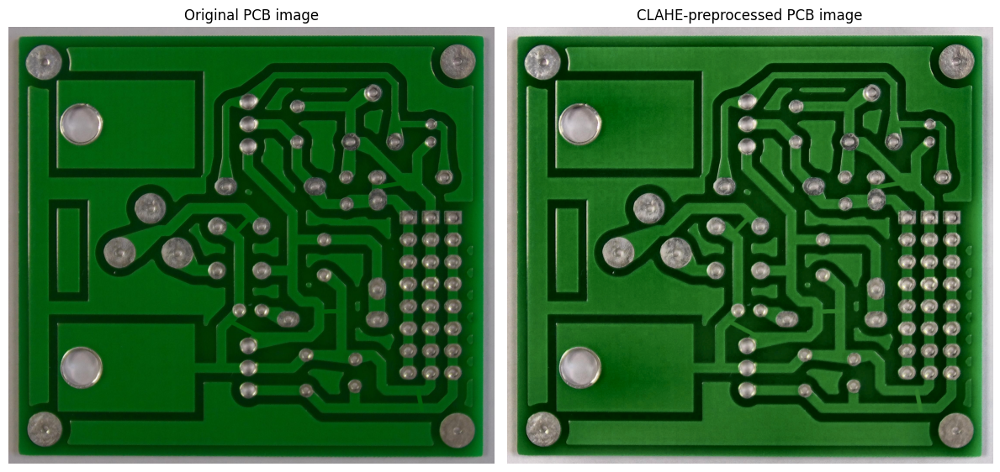

Image: 10_short_02_jpg.rf.cb0c13bba5eeebff39739d629d44c57d.jpg
Original dimensions: (2016, 2240)
Processed dimensions: (2016, 2240)


In [15]:
# ============================================================
# CELL 13B — ORIGINAL VS PREPROCESSED PREVIEW
# ============================================================

import matplotlib.pyplot as plt
from PIL import Image
import random

sample_dir = SOURCE_ROOT / "train" / "images"

sample_images = [
    p for p in sample_dir.iterdir()
    if p.suffix.lower() in IMAGE_EXTENSIONS
]

sample_path = random.choice(sample_images)

original = cv2.imread(str(sample_path))
processed = preprocess_pcb_image(original)

original_rgb = cv2.cvtColor(
    original,
    cv2.COLOR_BGR2RGB
)

processed_rgb = cv2.cvtColor(
    processed,
    cv2.COLOR_BGR2RGB
)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(original_rgb)
axes[0].set_title("Original PCB image")
axes[0].axis("off")

axes[1].imshow(processed_rgb)
axes[1].set_title("CLAHE-preprocessed PCB image")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Image:", sample_path.name)
print("Original dimensions:", original.shape[:2])
print("Processed dimensions:", processed.shape[:2])

In [16]:
# ============================================================
# CELL 13C — CUSTOM COMPETITION METRIC TRAINER
# mAP@50:90 used for BEST CHECKPOINT SELECTION
# ============================================================

import numpy as np

from ultralytics import YOLO
from ultralytics.models.yolo.detect import DetectionTrainer
from ultralytics.utils import LOGGER


class PCBCompetitionTrainer(DetectionTrainer):

    def validate(self):

        # Preserve the previous competition-best fitness.
        previous_best = self.best_fitness

        # Run the normal Ultralytics validation.
        metrics, _ = super().validate()

        if metrics is None:
            return metrics, None

        box_metrics = self.validator.metrics.box

        all_ap = np.asarray(
            box_metrics.all_ap,
            dtype=np.float64
        )

        class_ids = np.asarray(
            box_metrics.ap_class_index,
            dtype=int
        )

        # This competition requires all six classes.
        expected_classes = set(range(6))

        if set(class_ids.tolist()) != expected_classes:
            raise RuntimeError(
                f"Expected all six classes. Found: {class_ids.tolist()}"
            )

        if all_ap.ndim != 2 or all_ap.shape[1] != 10:
            raise RuntimeError(
                f"Unexpected AP matrix shape: {all_ap.shape}"
            )

        # Map rows back to fixed class order.
        ap_by_class = np.full(
            (6, 10),
            np.nan,
            dtype=np.float64
        )

        for row, class_id in enumerate(class_ids):
            ap_by_class[class_id] = all_ap[row]

        # Competition thresholds: 0.50, 0.55, ..., 0.90.
        competition_map = float(
            np.mean(ap_by_class[:, :9])
        )

        if not np.isfinite(competition_map):
            raise RuntimeError(
                "Competition mAP@50:90 is not finite."
            )

        # Add custom metric to the training metrics dictionary.
        metrics["metrics/mAP50-90(B)"] = competition_map

        # Override Ultralytics default mAP50:95 fitness.
        fitness = competition_map

        if previous_best is None:
            self.best_fitness = fitness
        else:
            self.best_fitness = max(
                float(previous_best),
                fitness
            )

        LOGGER.info(
            f"COMPETITION mAP@50:90: {competition_map:.5f}"
        )

        LOGGER.info("Per-class competition AP@50:90:")

        for class_id, class_name in enumerate(CLASS_NAMES):

            class_score = float(
                np.mean(ap_by_class[class_id, :9])
            )

            LOGGER.info(
                f"  {class_name}: {class_score:.5f}"
            )

        return metrics, fitness


print("PCBCompetitionTrainer ready.")
print("Checkpoint selection metric: mAP@50:90")

PCBCompetitionTrainer ready.
Checkpoint selection metric: mAP@50:90


In [18]:
# ============================================================
# CELL 14 — YOLO26m TRAINING AT 896 x 896
#
# - Automatically searches for previous YOLO26m best.pt
# - Searches checkpoint ZIP archives
# - Falls back to yolo26m.pt if previous checkpoint is lost
# - Applies CLAHE-preprocessed dataset
# - Selects best.pt using competition mAP@50:90
# ============================================================

from pathlib import Path
import zipfile
import shutil
import numpy as np
import torch
import yaml

from ultralytics import YOLO
from ultralytics.models.yolo.detect import DetectionTrainer
from ultralytics.utils import LOGGER


# ============================================================
# 1. CONFIGURATION
# ============================================================

CLASS_NAMES = [
    "missing_hole",
    "mouse_bite",
    "open_circuit",
    "short",
    "spur",
    "spurious_copper"
]

# CLAHE-preprocessed dataset created by Cell 13A.
DATA_YAML_896 = Path(
    "/kaggle/working/pcb_defects_clahe_v1/pcb_data_clahe.yaml"
)

if not DATA_YAML_896.exists():
    raise FileNotFoundError(
        "Preprocessed dataset YAML not found.\n"
        "Run Cell 13A first to generate the CLAHE dataset."
    )

with open(DATA_YAML_896, "r") as f:
    dataset_config = yaml.safe_load(f)

assert dataset_config["nc"] == 6
assert dataset_config["names"] == CLASS_NAMES

# Training parameters
IMAGE_SIZE = 896
EPOCHS = 120
PATIENCE = 30

PROJECT_DIR = "/kaggle/working/pcb_runs_896"
RUN_NAME = "YOLO26m_896_CLAHE_Competition"

# GPU configuration
GPU_COUNT = torch.cuda.device_count()

if GPU_COUNT == 0:
    raise RuntimeError("No CUDA GPU detected.")

DEVICE = [0, 1] if GPU_COUNT >= 2 else 0
BATCH_SIZE = 8 if GPU_COUNT >= 2 else 4

print("Available GPUs:", GPU_COUNT)
print("Training device:", DEVICE)
print("Global batch size:", BATCH_SIZE)


# ============================================================
# 2. FIND PREVIOUS 640 YOLO26m CHECKPOINT
# ============================================================

SEARCH_ROOTS = [
    Path("/kaggle/working"),
    Path("/kaggle/input")
]

EXCLUDE_TERMS = [
    "896",
    "clahe_competition"
]

found_checkpoints = {}

# ------------------------------------------------------------
# 2A. Search directly for best.pt
# ------------------------------------------------------------

for root in SEARCH_ROOTS:

    if not root.exists():
        continue

    for checkpoint in root.rglob("best.pt"):

        if not checkpoint.is_file():
            continue

        path_lower = str(checkpoint).lower()

        if any(term in path_lower for term in EXCLUDE_TERMS):
            continue

        found_checkpoints[str(checkpoint.resolve())] = checkpoint


# ------------------------------------------------------------
# 2B. Search checkpoint ZIP archives
# ------------------------------------------------------------

RESTORE_DIR = Path(
    "/kaggle/working/restored_640_checkpoint"
)

RESTORE_DIR.mkdir(parents=True, exist_ok=True)

for root in SEARCH_ROOTS:

    if not root.exists():
        continue

    for archive_path in root.rglob("*.zip"):

        try:
            with zipfile.ZipFile(archive_path, "r") as archive:

                matching_members = [
                    member for member in archive.infolist()
                    if Path(member.filename).name == "best.pt"
                    and "896" not in member.filename.lower()
                    and "clahe" not in member.filename.lower()
                ]

                for member in matching_members:

                    destination = (
                        RESTORE_DIR /
                        f"{archive_path.stem}_best.pt"
                    )

                    if not destination.exists():

                        with archive.open(member) as source:
                            with open(destination, "wb") as target:
                                shutil.copyfileobj(source, target)

                    found_checkpoints[
                        str(destination.resolve())
                    ] = destination

        except (zipfile.BadZipFile, OSError):
            continue


# ------------------------------------------------------------
# 2C. Display discovered checkpoints
# ------------------------------------------------------------

candidates = list(found_checkpoints.values())

print("\nDISCOVERED CHECKPOINTS")

for index, checkpoint in enumerate(candidates, 1):

    print(
        f"{index}. {checkpoint} | "
        f"{checkpoint.stat().st_size / 1024**2:.2f} MB"
    )


# ------------------------------------------------------------
# 2D. Select checkpoint safely
# ------------------------------------------------------------

preferred_names = [
    "YOLO26m_150epochs_v1",
    "YOLO26m_PCB_Final",
    "PCB_Defect_Submission",
    "PCB_Checkpoints"
]

START_WEIGHTS = None

for preferred in preferred_names:

    matching = [
        path for path in candidates
        if preferred.lower() in str(path).lower()
    ]

    if matching:
        START_WEIGHTS = matching[0]
        break

if START_WEIGHTS is None:

    if len(candidates) == 1:
        START_WEIGHTS = candidates[0]

    elif len(candidates) > 1:
        raise RuntimeError(
            "Multiple checkpoints were found, but their identity "
            "cannot be established safely.\n"
            "Inspect the printed paths and set START_WEIGHTS "
            "manually to your original YOLO26m 640 best.pt."
        )


# ============================================================
# 3. CHOOSE TRAINING MODE
# ============================================================

if START_WEIGHTS is not None:

    TRAINING_MODE = "FINE-TUNING FROM PREVIOUS YOLO26m CHECKPOINT"

    print("\nPrevious checkpoint found:")
    print(START_WEIGHTS)

    # Load and verify architecture/classes.
    model = YOLO(str(START_WEIGHTS))

    model_yaml = getattr(model.model, "yaml", {})

    if model_yaml.get("nc") != 6:
        raise RuntimeError(
            "The selected checkpoint does not have six classes. "
            "Check that this is your trained PCB model."
        )

    scale = model_yaml.get("scale")

    if scale is not None and str(scale).lower() != "m":
        raise RuntimeError(
            f"Expected YOLO26m, but detected model scale: {scale}"
        )

    # Conservative learning rate for fine-tuning.
    OPTIMIZER = "AdamW"
    LEARNING_RATE = 0.0005

else:

    TRAINING_MODE = "FRESH TRANSFER LEARNING FROM YOLO26m PRETRAINED WEIGHTS"

    print("\nWARNING: No previous 640 best.pt was found.")
    print("Using official YOLO26m pretrained weights instead.")
    print("This is NOT fine-tuning from your previous 640 model.")

    model = YOLO("yolo26m.pt")

    OPTIMIZER = "AdamW"
    LEARNING_RATE = 0.001


print("\nTRAINING MODE:", TRAINING_MODE)
print("Starting weights:", model.ckpt_path if hasattr(model, "ckpt_path") else "Loaded model")
print("Optimizer:", OPTIMIZER)
print("Learning rate:", LEARNING_RATE)


# ============================================================
# 4. CUSTOM COMPETITION TRAINER
# ============================================================

class PCBCompetitionTrainer(DetectionTrainer):

    def validate(self):

        # Preserve previous competition-best score.
        previous_best = self.best_fitness

        # Run standard Ultralytics validation.
        metrics, fitness = super().validate()

        if metrics is None:
            return metrics, fitness

        box_metrics = self.validator.metrics.box

        all_ap = np.asarray(
            box_metrics.all_ap,
            dtype=np.float64
        )

        class_ids = np.asarray(
            box_metrics.ap_class_index,
            dtype=int
        )

        if all_ap.ndim != 2 or all_ap.shape[1] != 10:
            raise RuntimeError(
                f"Unexpected AP array shape: {all_ap.shape}"
            )

        if set(class_ids.tolist()) != set(range(6)):
            raise RuntimeError(
                f"Expected all six classes. Found: {class_ids.tolist()}"
            )

        # Restore fixed competition class order.
        ap_by_class = np.full(
            (6, 10),
            np.nan,
            dtype=np.float64
        )

        for row, class_id in enumerate(class_ids):
            ap_by_class[class_id] = all_ap[row]

        # Competition metric: IoU 0.50 to 0.90.
        competition_map = float(
            np.mean(ap_by_class[:, :9])
        )

        if not np.isfinite(competition_map):
            raise RuntimeError(
                "Invalid competition mAP@50:90."
            )

        # Add custom metric to training history.
        metrics["metrics/mAP50-90(B)"] = competition_map

        # Select best.pt using competition metric.
        fitness = competition_map

        self.best_fitness = (
            fitness if previous_best is None
            else max(float(previous_best), fitness)
        )

        LOGGER.info(
            f"COMPETITION mAP@50:90: {competition_map:.5f}"
        )

        LOGGER.info("Per-class AP@50:90:")

        for class_id, class_name in enumerate(CLASS_NAMES):

            class_score = float(
                np.mean(ap_by_class[class_id, :9])
            )

            LOGGER.info(
                f"{class_name}: {class_score:.5f}"
            )

        return metrics, fitness


print("\nCustom competition trainer ready.")
print("Best checkpoint selection: mAP@50:90")


# ============================================================
# 5. START YOLO26m TRAINING
# ============================================================

print("\n" + "=" * 65)
print("STARTING YOLO26m 896 x 896 TRAINING")
print("=" * 65)

results = model.train(

    # Preprocessed CLAHE dataset.
    data=str(DATA_YAML_896),

    # Input and training duration.
    imgsz=IMAGE_SIZE,
    epochs=EPOCHS,
    batch=BATCH_SIZE,

    # GPU.
    device=DEVICE,
    workers=2,

    # Fine-tuning / transfer-learning optimizer.
    optimizer=OPTIMIZER,
    lr0=LEARNING_RATE,
    lrf=0.01,
    weight_decay=0.0005,
    warmup_epochs=2,
    cos_lr=True,

    # Early stopping.
    patience=PATIENCE,

    # PCB augmentation.
    hsv_h=0.005,
    hsv_s=0.08,
    hsv_v=0.12,

    degrees=0.0,
    translate=0.03,
    scale=0.10,

    fliplr=0.5,
    flipud=0.5,

    mosaic=0.10,
    close_mosaic=10,
    mixup=0.0,
    copy_paste=0.0,

    # Fixed CLAHE already applied to all images.
    augmentations=[],

    # Dataset configuration.
    cls_pw=0.0,

    # Training controls.
    amp=True,
    cache=False,
    multi_scale=False,

    # Checkpoints and plots.
    save=True,
    save_period=5,
    plots=True,
    val=True,

    # Output.
    project=PROJECT_DIR,
    name=RUN_NAME,
    exist_ok=False,

    # New training run, not resume.
    resume=False,

    seed=42,
    deterministic=True,

    # Competition metric trainer.
    trainer=PCBCompetitionTrainer
)


# ============================================================
# 6. FINAL TRAINING PATHS
# ============================================================

RUN_DIR = Path(model.trainer.save_dir)

BEST_MODEL = RUN_DIR / "weights" / "best.pt"
LAST_MODEL = RUN_DIR / "weights" / "last.pt"

print("\n" + "=" * 65)
print("TRAINING FINISHED")
print("=" * 65)

print("Training mode:", TRAINING_MODE)
print("Run directory:", RUN_DIR)
print("Best checkpoint:", BEST_MODEL)
print("Last checkpoint:", LAST_MODEL)

assert BEST_MODEL.exists(), "best.pt was not generated."
assert LAST_MODEL.exists(), "last.pt was not generated."

print("\nYOLO26m training completed successfully.")

Available GPUs: 2
Training device: [0, 1]
Global batch size: 8

DISCOVERED CHECKPOINTS

Using official YOLO26m pretrained weights instead.
This is NOT fine-tuning from your previous 640 model.

TRAINING MODE: FRESH TRANSFER LEARNING FROM YOLO26m PRETRAINED WEIGHTS
Starting weights: yolo26m.pt
Optimizer: AdamW
Learning rate: 0.001

Custom competition trainer ready.
Best checkpoint selection: mAP@50:90

STARTING YOLO26m 896 x 896 TRAINING
Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, augmentations=[], auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/pcb_defects_clahe_v1/pcb_da

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      2/120      7.12G       2.33      2.482   0.004421         18        896: 100% ━━━━━━━━━━━━ 235/235 3.9it/s 59.6s0.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 33/33 4.2it/s 7.8s0.2s
                   all        517       2218      0.474      0.405      0.402      0.146
COMPETITION mAP@50:90: 0.16197
Per-class AP@50:90:
missing_hole: 0.30327
mouse_bite: 0.12536
open_circuit: 0.09059
short: 0.18084
spur: 0.11364
spurious_copper: 0.15813

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      3/120      7.12G      2.238      2.247   0.004162         20        896: 100% ━━━━━━━━━━━━ 235/235 4.0it/s 59.3s0.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 33/33 4.3it/s 7.7s0.2s
                   all        517       2218      0.597      0.391      0.

In [19]:
# ============================================================
# CELL 15 — FINAL COMPETITION METRIC EVALUATION
# ============================================================

from pathlib import Path
from ultralytics import YOLO
import numpy as np
import pandas as pd

RUN_DIR = Path(model.trainer.save_dir)
BEST_896 = RUN_DIR / "weights" / "best.pt"

assert BEST_896.exists(), f"Checkpoint missing: {BEST_896}"

evaluation_model = YOLO(str(BEST_896))

val_results = evaluation_model.val(
    data=str(DATA_YAML_896),
    split="val",
    imgsz=896,
    batch=4,
    device=0,
    workers=2,
    plots=True
)

ap = np.asarray(
    val_results.box.all_ap,
    dtype=np.float64
)

class_ids = np.asarray(
    val_results.box.ap_class_index,
    dtype=int
)

ap_by_class = np.full((6, 10), np.nan)

for row, class_id in enumerate(class_ids):
    ap_by_class[class_id] = ap[row]

assert not np.isnan(ap_by_class[:, :9]).any()

competition_map = float(
    ap_by_class[:, :9].mean()
)

print("=" * 55)
print("FINAL PCB COMPETITION EVALUATION")
print("=" * 55)

print(f"mAP@50:95 : {val_results.box.map:.5f}")
print(f"mAP@50    : {val_results.box.map50:.5f}")
print(f"mAP@50:90 : {competition_map:.5f}")
print(f"Precision : {val_results.box.mp:.5f}")
print(f"Recall    : {val_results.box.mr:.5f}")

rows = []

for class_id, class_name in enumerate(CLASS_NAMES):

    score = float(
        ap_by_class[class_id, :9].mean()
    )

    rows.append({
        "Class": class_name,
        "AP50": float(ap_by_class[class_id, 0]),
        "AP75": float(ap_by_class[class_id, 5]),
        "AP90": float(ap_by_class[class_id, 8]),
        "AP50_90": score
    })

class_results = pd.DataFrame(rows)

display(class_results)

class_results.to_csv(
    RUN_DIR / "competition_class_metrics.csv",
    index=False
)

print("Best checkpoint:", BEST_896)

Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO26m summary (fused): 130 layers, 20,354,078 parameters, 0 gradients, 68.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3138.7±1000.1 MB/s, size: 710.9 KB)
val: Scanning /kaggle/working/pcb_defects_clahe_v1/valid/labels.cache... 517 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 517/517 135.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 130/130 3.5it/s 36.7s0.3s
                   all        517       2218       0.96      0.953       0.97      0.505
          missing_hole         93        387      0.988       0.99      0.994      0.572
            mouse_bite         87        377      0.951      0.932      0.968      0.485
          open_circuit         87        360      0.941      0.926      0.954      0.466
                 short         74        316      0.947      0.968      0.974      0.516
             

,Class,AP50,AP75,AP90,AP50_90
0,missing_hole,0.993506,0.598353,0.012377,0.636009
1,mouse_bite,0.967778,0.415346,0.008043,0.539246
2,open_circuit,0.954062,0.357789,0.002805,0.517637
3,short,0.974184,0.453288,0.004853,0.573535
4,spur,0.946280,0.372097,0.005637,0.517282
5,spurious_copper,0.983954,0.488000,0.006162,0.582622


Best checkpoint: /kaggle/working/pcb_runs_896/YOLO26m_896_CLAHE_Competition/weights/best.pt


In [20]:

# # CELL 14 — YOLO26m | 150 EPOCHS | 2x T4
# # CHECKPOINT SAVING + INTERRUPTED TRAINING RESUMPTION

# from ultralytics import YOLO
# from pathlib import Path
# import torch

# # ==========================================
# # 1. CONFIGURATION
# # ==========================================

# DATA_YAML = Path("/kaggle/working/pcb_data.yaml")

# PROJECT = Path("/kaggle/working/pcb_runs")

# RUN_NAME = "YOLO26m_150epochs_v1"

# RUN_DIR = PROJECT / RUN_NAME

# # FIRST RUN: None
# #
# # AFTER INTERRUPTION:
# # RESUME_FROM = str(RUN_DIR / "weights" / "last.pt")
# #
# # NEW KAGGLE SESSION:
# # Set this to the attached checkpoint's last.pt path.

# RESUME_FROM = None

# # ==========================================
# # 2. ENVIRONMENT VERIFICATION
# # ==========================================

# assert DATA_YAML.exists(), "Dataset YAML missing."

# assert torch.cuda.is_available(), "CUDA unavailable."

# assert torch.cuda.device_count() == 2, (
#     "Expected two GPUs. Select Kaggle T4 x2."
# )

# print("GPU 0:", torch.cuda.get_device_name(0))
# print("GPU 1:", torch.cuda.get_device_name(1))

# print("Target epochs: 150")
# print("Patience: 25")
# print("Class weighting:", CLS_PW)

# # ==========================================
# # 3. RESUME OR START NEW RUN
# # ==========================================

# if RESUME_FROM is not None:

#     # RESUME EXISTING TRAINING

#     CHECKPOINT = Path(RESUME_FROM)

#     assert CHECKPOINT.exists(), (
#         f"Checkpoint not found: {CHECKPOINT}"
#     )

#     assert CHECKPOINT.name == "last.pt", (
#         "Use last.pt for interrupted training."
#     )

#     print("\nRESUMING TRAINING")
#     print("Checkpoint:", CHECKPOINT)

#     model = YOLO(str(CHECKPOINT))

#     results = model.train(
#         resume=True,
#         device=[0, 1],
#         workers=2,
#         patience=15
#     )

# else:

#     # START FRESH 150-EPOCH RUN

#     if RUN_DIR.exists() and any(RUN_DIR.iterdir()):
#         raise FileExistsError(
#             f"Run already exists: {RUN_DIR}\n"
#             "Set RESUME_FROM to last.pt instead."
#         )

#     print("\nSTARTING FRESH YOLO26m TRAINING")

#     model = YOLO("yolo26m.pt")

#     results = model.train(

#         # Dataset
#         data=str(DATA_YAML),

#         # Architecture
#         imgsz=640,
#         pretrained=True,

#         # BOTH T4 GPUs
#         device=[0, 1],
#         batch=16,

#         # Loading
#         workers=2,
#         cache=False,

#         # Mixed precision
#         amp=True,

#         # TOTAL TRAINING TARGET
#         epochs=150,

#         # Early stopping
#         patience=25,

#         # NO time limit
#         # Do not specify time=0.55 or time=1.0.

#         # Optimisation
#         optimizer="auto",
#         seed=42,
#         deterministic=False,

#         # Class imbalance
#         cls_pw=CLS_PW,

#         # Brightness and colour augmentation
#         hsv_h=0.005,
#         hsv_s=0.10,
#         hsv_v=0.15,

#         # Geometric augmentation
#         fliplr=0.5,
#         flipud=0.5,
#         degrees=0.0,
#         translate=0.05,
#         scale=0.20,

#         # Mosaic
#         mosaic=0.25,
#         close_mosaic=10,

#         # Image mixing
#         mixup=0.0,
#         copy_paste=0.0,

#         # Checkpoint saving
#         save=True,
#         save_period=5,

#         # Validation
#         val=True,
#         plots=True,

#         # Output
#         project=str(PROJECT),
#         name=RUN_NAME,
#         exist_ok=False
#     )

# print("\nTRAINING FINISHED OR STOPPED.")


In [21]:
# ============================================================
# CELL 15 — SAVE MODEL WEIGHTS AND TRAINING HISTORY
# YOLO26m 896 + CLAHE + Competition mAP@50:90
# ============================================================

from pathlib import Path
import shutil
import pandas as pd
import json

# --------------------------------------------------
# 1. Locate training outputs
# --------------------------------------------------

RUN_NAME = "YOLO26m_896_CLAHE_Competition"

RUN_DIR = (
    Path("/kaggle/working/pcb_runs_896") / RUN_NAME
)

WEIGHTS_DIR = RUN_DIR / "weights"

BEST_MODEL = WEIGHTS_DIR / "best.pt"
LAST_MODEL = WEIGHTS_DIR / "last.pt"

RESULTS_CSV = RUN_DIR / "results.csv"

OUTPUT_DIR = Path(
    "/kaggle/working/PCB_Defect_Submission_896"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Training directory:", RUN_DIR)

# --------------------------------------------------
# 2. Verify checkpoints
# --------------------------------------------------

if not RUN_DIR.exists():
    raise FileNotFoundError(
        f"Training directory not found: {RUN_DIR}"
    )

if not BEST_MODEL.exists():
    raise FileNotFoundError(
        "best.pt not found. Check validation completion."
    )

if not LAST_MODEL.exists():
    raise FileNotFoundError(
        "last.pt not found. Check training completion."
    )

# --------------------------------------------------
# 3. Save important model weights
# --------------------------------------------------

for source in [BEST_MODEL, LAST_MODEL]:

    destination = OUTPUT_DIR / source.name

    shutil.copy2(source, destination)

    print(
        "Saved:", source.name,
        f"({source.stat().st_size / 1024**2:.2f} MB)"
    )

# --------------------------------------------------
# 4. Save training history
# --------------------------------------------------

if RESULTS_CSV.exists():

    shutil.copy2(
        RESULTS_CSV,
        OUTPUT_DIR / "results.csv"
    )

    training_history = pd.read_csv(RESULTS_CSV)

    print("\nLATEST TRAINING RECORDS")
    display(training_history.tail(10))

else:
    print("WARNING: results.csv not found.")

# --------------------------------------------------
# 5. Save training plots
# --------------------------------------------------

plot_patterns = [
    "results.png",
    "confusion_matrix*.png",
    "labels*.jpg",
    "Box*curve.png",
    "train_batch*.jpg",
    "val_batch*.jpg"
]

saved_plots = set()

for pattern in plot_patterns:

    for source in RUN_DIR.glob(pattern):

        if source.is_file() and source.name not in saved_plots:

            shutil.copy2(
                source,
                OUTPUT_DIR / source.name
            )

            saved_plots.add(source.name)

            print("Saved plot:", source.name)

# --------------------------------------------------
# 6. Save dataset configuration
# --------------------------------------------------

if Path(DATA_YAML_896).exists():

    shutil.copy2(
        DATA_YAML_896,
        OUTPUT_DIR / "data.yaml"
    )

# --------------------------------------------------
# 7. Save Ultralytics training arguments
# --------------------------------------------------

ARGS_FILE = RUN_DIR / "args.yaml"

if ARGS_FILE.exists():

    shutil.copy2(
        ARGS_FILE,
        OUTPUT_DIR / "args.yaml"
    )

# --------------------------------------------------
# 8. Save experiment configuration
# --------------------------------------------------

training_config = {

    "model": "YOLO26m",
    "initial_weights": "Previous YOLO26m best.pt",

    "image_size": 896,
    "batch_size": 8,
    "gpu": "2 x Tesla T4",

    "epochs_max": 120,
    "patience": 30,

    "optimizer": "AdamW",
    "initial_learning_rate": 0.0005,
    "final_lr_factor": 0.01,
    "weight_decay": 0.0005,
    "warmup_epochs": 2,
    "cosine_lr": True,

    "competition_metric": "mAP@50:90",
    "checkpoint_selection": "mAP@50:90",

    "cross_validation": False,

    "preprocessing": {
        "method": "CLAHE",
        "enabled": True,
        "color_space": "LAB",
        "channel": "L",
        "clip_limit": 1.5,
        "tile_grid_size": [8, 8]
    },

    "gamma_correction": False,
    "white_balance": False,
    "sharpening": False,
    "denoising": False,

    "augmentation": {
        "hsv_h": 0.005,
        "hsv_s": 0.08,
        "hsv_v": 0.12,
        "translate": 0.03,
        "scale": 0.10,
        "fliplr": 0.5,
        "flipud": 0.5,
        "mosaic": 0.10,
        "mixup": 0.0,
        "copy_paste": 0.0,
        "albumentations": []
    },

    "class_weight": 0.0,

    "class_names": CLASS_NAMES
}

(OUTPUT_DIR / "training_config.json").write_text(
    json.dumps(training_config, indent=4)
)

# --------------------------------------------------
# 9. Final output report
# --------------------------------------------------

print("\n" + "=" * 60)
print("MODEL AND TRAINING HISTORY SAVED")
print("=" * 60)

for file in sorted(OUTPUT_DIR.iterdir()):

    if file.is_file():

        print(
            file.name,
            f"{file.stat().st_size / 1024**2:.2f} MB"
        )

print("\nOutput directory:", OUTPUT_DIR)

Training directory: /kaggle/working/pcb_runs_896/YOLO26m_896_CLAHE_Competition
Saved: best.pt (42.06 MB)
Saved: last.pt (42.06 MB)

LATEST TRAINING RECORDS


,epoch,time,train/box_loss,train/cls_loss,train/l1_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/l1_loss,metrics/mAP50-90(B),lr/pg0,lr/pg1,lr/pg2
110,111,7530.41,1.33695,0.69337,0.00229,0.96171,0.95101,0.97033,0.49920,1.66370,0.74049,0.00287,0.554656,0.000027,0.000027,0.000027
111,112,7597.99,1.33460,0.68750,0.00229,0.96208,0.95235,0.97134,0.50316,1.66214,0.72867,0.00287,0.559054,0.000024,0.000024,0.000024
112,113,7666.32,1.34180,0.69164,0.00228,0.96151,0.95264,0.97133,0.50247,1.66383,0.72673,0.00287,0.558296,0.000021,0.000021,0.000021
113,114,7733.96,1.34147,0.67879,0.00231,0.96125,0.95411,0.97018,0.49722,1.67365,0.72463,0.00289,0.552446,0.000018,0.000018,0.000018
114,115,7801.77,1.32248,0.68209,0.00228,0.96278,0.95195,0.97204,0.50196,1.65874,0.72841,0.00286,0.557727,0.000016,0.000016,0.000016
115,116,7869.54,1.33242,0.70600,0.00229,0.96316,0.95359,0.97388,0.50262,1.66208,0.72433,0.00286,0.558459,0.000014,0.000014,0.000014
116,117,7937.23,1.31302,0.65325,0.00224,0.96192,0.95367,0.97160,0.50180,1.66190,0.72495,0.00286,0.557544,0.000013,0.000013,0.000013
117,118,8004.84,1.34265,0.71455,0.00230,0.96113,0.95412,0.97170,0.50172,1.65886,0.72372,0.00286,0.557466,0.000012,0.000012,0.000012
118,119,8072.36,1.32165,0.65777,0.00223,0.96008,0.95296,0.97184,0.50170,1.65682,0.72353,0.00285,0.557439,0.000011,0.000011,0.000011
119,120,8139.86,1.32079,0.65714,0.00225,0.96196,0.95520,0.97229,0.49998,1.66284,0.72226,0.00287,0.555529,0.000010,0.000010,0.000010


Saved plot: results.png
Saved plot: confusion_matrix.png
Saved plot: confusion_matrix_normalized.png
Saved plot: labels.jpg
Saved plot: BoxF1_curve.png
Saved plot: BoxR_curve.png
Saved plot: BoxP_curve.png
Saved plot: BoxPR_curve.png
Saved plot: train_batch25851.jpg
Saved plot: train_batch1.jpg
Saved plot: train_batch25850.jpg
Saved plot: train_batch2.jpg
Saved plot: train_batch0.jpg
Saved plot: train_batch25852.jpg
Saved plot: val_batch1_labels.jpg
Saved plot: val_batch0_pred.jpg
Saved plot: val_batch0_labels.jpg
Saved plot: val_batch2_pred.jpg
Saved plot: val_batch2_labels.jpg
Saved plot: val_batch1_pred.jpg

MODEL AND TRAINING HISTORY SAVED
BoxF1_curve.png 0.24 MB
BoxPR_curve.png 0.15 MB
BoxP_curve.png 0.16 MB
BoxR_curve.png 0.22 MB
args.yaml 0.00 MB
best.pt 42.06 MB
confusion_matrix.png 0.18 MB
confusion_matrix_normalized.png 0.18 MB
data.yaml 0.00 MB
labels.jpg 0.14 MB
last.pt 42.06 MB
results.csv 0.02 MB
results.png 0.27 MB
train_batch0.jpg 0.42 MB
train_batch1.jpg 0.45 MB
train_

In [22]:
# ============================================================
# CELL 16 — CREATE CHECKPOINT BACKUP
# YOLO26m 896 CLAHE Experiment
# ============================================================

from pathlib import Path
import zipfile
import shutil

# --------------------------------------------------
# 1. Checkpoint locations
# --------------------------------------------------

RUN_DIR = (
    Path("/kaggle/working/pcb_runs_896")
    / "YOLO26m_896_CLAHE_Competition"
)

WEIGHTS_DIR = RUN_DIR / "weights"

BACKUP_DIR = Path(
    "/kaggle/working/PCB_Checkpoints_896"
)

BACKUP_ZIP = Path(
    "/kaggle/working/PCB_Checkpoints_896.zip"
)

# Remove previous backup to avoid mixing experiments.
if BACKUP_DIR.exists():
    shutil.rmtree(BACKUP_DIR)

BACKUP_DIR.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 2. Collect important checkpoints
# --------------------------------------------------

checkpoints = [
    WEIGHTS_DIR / "last.pt",
    WEIGHTS_DIR / "best.pt"
]

periodic_checkpoints = sorted(
    WEIGHTS_DIR.glob("epoch*.pt"),
    key=lambda p: p.name
)

checkpoints.extend(periodic_checkpoints)

available_checkpoints = [
    p for p in checkpoints
    if p.exists()
]

if not (WEIGHTS_DIR / "last.pt").exists():
    raise FileNotFoundError(
        "last.pt unavailable. Cannot create resume backup."
    )

if not (WEIGHTS_DIR / "best.pt").exists():
    raise FileNotFoundError(
        "best.pt unavailable. Inspect training output."
    )

# --------------------------------------------------
# 3. Copy checkpoints
# --------------------------------------------------

for checkpoint in available_checkpoints:

    destination = BACKUP_DIR / checkpoint.name

    shutil.copy2(
        checkpoint,
        destination
    )

    print(
        "Backup completed:",
        checkpoint.name,
        f"({checkpoint.stat().st_size / 1024**2:.2f} MB)"
    )

# --------------------------------------------------
# 4. Create ZIP archive
# --------------------------------------------------

if BACKUP_ZIP.exists():
    BACKUP_ZIP.unlink()

with zipfile.ZipFile(
    BACKUP_ZIP,
    "w",
    compression=zipfile.ZIP_STORED
) as archive:

    for checkpoint in sorted(BACKUP_DIR.glob("*.pt")):

        archive.write(
            checkpoint,
            arcname=checkpoint.name
        )

# --------------------------------------------------
# 5. Verify ZIP contents
# --------------------------------------------------

with zipfile.ZipFile(BACKUP_ZIP, "r") as archive:

    archived_files = archive.namelist()

    assert "last.pt" in archived_files
    assert "best.pt" in archived_files

    print("\nCHECKPOINT ARCHIVE CONTENTS")

    for filename in archived_files:
        print(filename)

print("\nCheckpoint ZIP created successfully.")
print("Location:", BACKUP_ZIP)

print(
    "Archive size:",
    round(BACKUP_ZIP.stat().st_size / 1024**2, 2),
    "MB"
)

Backup completed: last.pt (42.06 MB)
Backup completed: best.pt (42.06 MB)
Backup completed: epoch0.pt (208.60 MB)
Backup completed: epoch10.pt (208.60 MB)
Backup completed: epoch100.pt (208.62 MB)
Backup completed: epoch105.pt (208.62 MB)
Backup completed: epoch110.pt (208.62 MB)
Backup completed: epoch115.pt (208.62 MB)
Backup completed: epoch15.pt (208.60 MB)
Backup completed: epoch20.pt (208.61 MB)
Backup completed: epoch25.pt (208.61 MB)
Backup completed: epoch30.pt (208.61 MB)
Backup completed: epoch35.pt (208.61 MB)
Backup completed: epoch40.pt (208.61 MB)
Backup completed: epoch45.pt (208.61 MB)
Backup completed: epoch5.pt (208.60 MB)
Backup completed: epoch50.pt (208.61 MB)
Backup completed: epoch55.pt (208.61 MB)
Backup completed: epoch60.pt (208.61 MB)
Backup completed: epoch65.pt (208.61 MB)
Backup completed: epoch70.pt (208.61 MB)
Backup completed: epoch75.pt (208.61 MB)
Backup completed: epoch80.pt (208.61 MB)
Backup completed: epoch85.pt (208.61 MB)
Backup completed: epoc

In [24]:
# ============================================================
# CELL 16B — FINAL VALIDATION REPORT
# Exact competition metric: mAP@50:90
# ============================================================

from pathlib import Path
from ultralytics import YOLO
import numpy as np
import pandas as pd
import json

RUN_DIR = Path(
    "/kaggle/working/pcb_runs_896/"
    "YOLO26m_896_CLAHE_Competition"
)

BEST_MODEL = RUN_DIR / "weights" / "best.pt"

DATA_YAML_896 = Path(
    "/kaggle/working/pcb_defects_clahe_v1/"
    "pcb_data_clahe.yaml"
)

CLASS_NAMES = [
    "missing_hole",
    "mouse_bite",
    "open_circuit",
    "short",
    "spur",
    "spurious_copper"
]

OUTPUT_DIR = Path(
    "/kaggle/working/PCB_Defect_Submission_896"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert BEST_MODEL.exists(), BEST_MODEL
assert DATA_YAML_896.exists(), DATA_YAML_896

# ------------------------------------------------------------
# 1. Load BEST checkpoint and independently validate
# ------------------------------------------------------------

evaluation_model = YOLO(str(BEST_MODEL))

val_results = evaluation_model.val(
    data=str(DATA_YAML_896),
    split="val",
    imgsz=896,
    batch=4,
    device=0,
    workers=2,
    conf=0.001,
    iou=0.7,
    max_det=300,
    plots=True,
    verbose=False
)

# Keep a consistent variable name for later cells.
val_metrics = val_results

# ------------------------------------------------------------
# 2. Extract per-class AP at all IoU thresholds
# ------------------------------------------------------------

box_metrics = val_results.box

all_ap = np.asarray(
    box_metrics.all_ap,
    dtype=np.float64
)

class_ids = np.asarray(
    box_metrics.ap_class_index,
    dtype=int
)

assert all_ap.shape == (6, 10), (
    f"Expected AP shape (6, 10), received {all_ap.shape}"
)

assert set(class_ids.tolist()) == set(range(6)), (
    f"Missing class IDs: {class_ids}"
)

# Fixed order: competition's six classes.
ap_by_class = np.full(
    (6, 10),
    np.nan,
    dtype=np.float64
)

for row, class_id in enumerate(class_ids):
    ap_by_class[class_id] = all_ap[row]

assert np.isfinite(ap_by_class).all()

# IoU thresholds: 0.50, 0.55, ..., 0.95.
iou_thresholds = np.round(
    np.arange(0.50, 0.951, 0.05),
    2
)

# ------------------------------------------------------------
# 3. Calculate competition metrics
# ------------------------------------------------------------

map_50 = float(ap_by_class[:, 0].mean())

map_50_90 = float(
    ap_by_class[:, :9].mean()
)

map_50_95 = float(
    ap_by_class.mean()
)

print("\n" + "=" * 65)
print("MODEL MAYHEM — PCB VALIDATION RESULTS")
print("=" * 65)

print(f"mAP@50:    {map_50:.6f}")
print(f"mAP@50:90: {map_50_90:.6f}  <-- PRIMARY METRIC")
print(f"mAP@50:95: {map_50_95:.6f}")
print(f"Precision: {val_results.box.mp:.6f}")
print(f"Recall:    {val_results.box.mr:.6f}")

# ------------------------------------------------------------
# 4. AP at each IoU threshold
# ------------------------------------------------------------

per_iou_df = pd.DataFrame({
    "IoU_threshold": iou_thresholds,
    "mean_AP_all_classes": ap_by_class.mean(axis=0)
})

print("\nAP AT EACH IoU THRESHOLD")
display(per_iou_df)

# ------------------------------------------------------------
# 5. Per-class report
# ------------------------------------------------------------

class_rows = []

for class_id, class_name in enumerate(CLASS_NAMES):

    class_ap = ap_by_class[class_id]

    class_rows.append({
        "class_name": class_name,
        "AP50": class_ap[0],
        "AP75": class_ap[5],
        "AP80": class_ap[6],
        "AP85": class_ap[7],
        "AP90": class_ap[8],
        "AP95": class_ap[9],
        "mAP50_90": class_ap[:9].mean()
    })

per_class_df = pd.DataFrame(class_rows)

print("\nPER-CLASS COMPETITION RESULTS")
display(per_class_df)

# ------------------------------------------------------------
# 6. Save reports
# ------------------------------------------------------------

per_iou_df.to_csv(
    OUTPUT_DIR / "per_iou_metrics.csv",
    index=False
)

per_class_df.to_csv(
    OUTPUT_DIR / "per_class_metrics.csv",
    index=False
)

metrics_report = {
    "model": "YOLO26m",
    "image_size": 896,
    "preprocessing": "CLAHE on LAB luminance",
    "validation_images": 517,
    "validation_instances": 2218,
    "mAP50": map_50,
    "mAP50_90": map_50_90,
    "mAP50_95": map_50_95,
    "precision": float(val_results.box.mp),
    "recall": float(val_results.box.mr),
    "primary_metric": "mAP@50:90",
    "iou_thresholds": iou_thresholds.tolist(),
    "best_checkpoint": str(BEST_MODEL)
}

(OUTPUT_DIR / "validation_metrics.json").write_text(
    json.dumps(metrics_report, indent=4)
)

print("\nValidation reports saved to:", OUTPUT_DIR)

Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO26m summary (fused): 130 layers, 20,354,078 parameters, 0 gradients, 68.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2854.8±986.8 MB/s, size: 299.2 KB)
val: Scanning /kaggle/working/pcb_defects_clahe_v1/valid/labels.cache... 517 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 517/517 240.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 130/130 3.5it/s 37.4s0.3s
                   all        517       2218       0.96      0.953       0.97      0.505
Speed: 1.5ms preprocess, 66.3ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /kaggle/working/runs/detect/val-2

MODEL MAYHEM — PCB VALIDATION RESULTS
mAP@50:    0.969960
mAP@50:90: 0.561055  <-- PRIMARY METRIC
mAP@50:95: 0.504960
Precision: 0.960366
Recall:    0.953006

AP AT EACH IoU THRESHOLD


,IoU_threshold,mean_AP_all_classes
0,0.50,0.969960
1,0.55,0.948934
2,0.60,0.901111
3,0.65,0.813084
4,0.70,0.672910
5,0.75,0.447479
6,0.80,0.222891
7,0.85,0.066480
8,0.90,0.006646
9,0.95,0.000100



PER-CLASS COMPETITION RESULTS


,class_name,AP50,AP75,AP80,AP85,AP90,AP95,mAP50_90
0,missing_hole,0.993506,0.598353,0.347787,0.111242,0.012377,0.000054,0.636009
1,mouse_bite,0.967778,0.415346,0.188603,0.062817,0.008043,0.000000,0.539246
2,open_circuit,0.954062,0.357789,0.166478,0.053346,0.002805,0.000099,0.517637
3,short,0.974184,0.453288,0.202941,0.062728,0.004853,0.000073,0.573535
4,spur,0.946280,0.372097,0.176922,0.041861,0.005637,0.000357,0.517282
5,spurious_copper,0.983954,0.488000,0.254615,0.066887,0.006162,0.000019,0.582622



Validation reports saved to: /kaggle/working/PCB_Defect_Submission_896


In [1]:
# ============================================================
# CELL 16C — FREE KAGGLE DISK SPACE
# ============================================================

from pathlib import Path
import shutil

RUN_DIR = Path(
    "/kaggle/working/pcb_runs_896/"
    "YOLO26m_896_CLAHE_Competition"
)

OUTPUT_DIR = Path(
    "/kaggle/working/PCB_Defect_Submission_896"
)

BACKUP_DIR = Path(
    "/kaggle/working/PCB_Checkpoints_896"
)

BACKUP_ZIP = Path(
    "/kaggle/working/PCB_Checkpoints_896.zip"
)

# Verify important model checkpoints before deletion.
required_checkpoints = [
    RUN_DIR / "weights" / "best.pt",
    RUN_DIR / "weights" / "last.pt",
    OUTPUT_DIR / "best.pt",
    OUTPUT_DIR / "last.pt"
]

for checkpoint in required_checkpoints:

    assert checkpoint.exists(), (
        f"Important checkpoint missing: {checkpoint}"
    )

    print(
        "Preserving:",
        checkpoint,
        f"{checkpoint.stat().st_size / 1024**2:.2f} MB"
    )

# Calculate backup sizes.
def folder_size(path):

    if not path.exists():
        return 0

    return sum(
        f.stat().st_size
        for f in path.rglob("*")
        if f.is_file()
    )

zip_size = (
    BACKUP_ZIP.stat().st_size
    if BACKUP_ZIP.exists()
    else 0
)

folder_bytes = folder_size(BACKUP_DIR)

print("\nBackup ZIP:", round(zip_size / 1024**3, 2), "GB")
print("Backup folder:", round(folder_bytes / 1024**3, 2), "GB")

# Delete duplicate backup files.
if BACKUP_ZIP.exists():
    BACKUP_ZIP.unlink()

if BACKUP_DIR.exists():
    shutil.rmtree(BACKUP_DIR)

print("\nDuplicate backups removed.")

usage = shutil.disk_usage("/kaggle/working")

print(
    "Remaining disk space:",
    round(usage.free / 1024**3, 2),
    "GB"
)

# Verify original checkpoints survived.
for checkpoint in required_checkpoints:
    assert checkpoint.exists()

print("All important model checkpoints are safe.")

Preserving: /kaggle/working/pcb_runs_896/YOLO26m_896_CLAHE_Competition/weights/best.pt 42.06 MB
Preserving: /kaggle/working/pcb_runs_896/YOLO26m_896_CLAHE_Competition/weights/last.pt 42.06 MB
Preserving: /kaggle/working/PCB_Defect_Submission_896/best.pt 42.06 MB
Preserving: /kaggle/working/PCB_Defect_Submission_896/last.pt 42.06 MB

Backup ZIP: 4.97 GB
Backup folder: 4.97 GB

Duplicate backups removed.
Remaining disk space: 8.25 GB
All important model checkpoints are safe.


In [2]:
# ============================================================
# CELL 16D — SINGLE IMAGE GPU INFERENCE TEST
# ============================================================

import torch
import gc
from pathlib import Path
from ultralytics import YOLO

BEST_MODEL = (
    "/kaggle/working/pcb_runs_896/"
    "YOLO26m_896_CLAHE_Competition/weights/best.pt"
)

PREP_TEST_DIR = Path(
    "/kaggle/working/pcb_defects_clahe_v1/test/images"
)

test_image = sorted(PREP_TEST_DIR.glob("*"))[0]

gc.collect()
torch.cuda.empty_cache()

print("Testing image:", test_image)

free, total = torch.cuda.mem_get_info(1)

print("GPU 1 free:", round(free / 1024**3, 2), "GB")

test_model = YOLO(BEST_MODEL)

test_result = test_model.predict(
    source=str(test_image),
    imgsz=896,
    batch=1,
    device="cuda:1",
    quantize=16,
    conf=0.001,
    iou=0.70,
    max_det=300,
    verbose=False
)

print("\nGPU INFERENCE TEST PASSED")
print("Device: CUDA 1")
print("Image:", test_image.name)

if test_result[0].boxes is not None:
    print("Detections:", len(test_result[0].boxes))

del test_result
del test_model

gc.collect()
torch.cuda.empty_cache()

print("GPU test completed.")

Testing image: /kaggle/working/pcb_defects_clahe_v1/test/images/01_missing_hole_02_jpg.rf.653e7a3d3352f695622f788241c5626d.jpg
GPU 1 free: 14.46 GB

GPU INFERENCE TEST PASSED
Device: CUDA 1
Image: 01_missing_hole_02_jpg.rf.653e7a3d3352f695622f788241c5626d.jpg
Detections: 10
GPU test completed.


## TESTING OF THE PCB DETECTION 

In [1]:
# ============================================================
# CELL 17 — CPU TEST INFERENCE + OFFICIAL COMPETITION CSV
#
# YOLO26m | 896 x 896 | CLAHE | CPU ONLY
#
# Compatible with Cells 18, 19A and 19B.
# ============================================================

from pathlib import Path
from ultralytics import YOLO
from tqdm.auto import tqdm

import pandas as pd
import numpy as np
import cv2
import json
import torch
import gc
import os

# ------------------------------------------------------------
# 1. PATHS AND CONFIGURATION
# ------------------------------------------------------------

BEST_MODEL = Path(
    "/kaggle/working/pcb_runs_896/"
    "YOLO26m_896_CLAHE_Competition/weights/best.pt"
)

RAW_TEST_DIR = Path(
    "/kaggle/input/datasets/abankitabehera/pcb-defects/test/images"
)

PREP_TEST_DIR = Path(
    "/kaggle/working/pcb_defects_clahe_v1/test/images"
)

OUTPUT_DIR = Path(
    "/kaggle/working/PCB_Defect_Submission_896"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PREDICTIONS_CSV = OUTPUT_DIR / "predictions.csv"
SUMMARY_CSV = OUTPUT_DIR / "test_image_summary.csv"

CLASS_NAMES = [
    "missing_hole",
    "mouse_bite",
    "open_circuit",
    "short",
    "spur",
    "spurious_copper"
]

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"
}

IMAGE_SIZE = 896

CONF_THRESHOLD = 0.001
NMS_IOU = 0.70
MAX_DETECTIONS = 300

BATCH_SIZE = 1

# ------------------------------------------------------------
# 2. VERIFY DATASET AND CHECKPOINT
# ------------------------------------------------------------

assert BEST_MODEL.exists(), (
    f"Checkpoint missing: {BEST_MODEL}"
)

assert RAW_TEST_DIR.exists()
assert PREP_TEST_DIR.exists()

raw_paths = sorted([
    p for p in RAW_TEST_DIR.iterdir()
    if p.is_file()
    and p.suffix.lower() in IMAGE_EXTENSIONS
])

prep_paths = sorted([
    p for p in PREP_TEST_DIR.iterdir()
    if p.is_file()
    and p.suffix.lower() in IMAGE_EXTENSIONS
])

raw_map = {p.name: p for p in raw_paths}
prep_map = {p.name: p for p in prep_paths}

assert set(raw_map) == set(prep_map), (
    "Original and CLAHE image filenames do not match."
)

assert len(raw_paths) == 189, (
    f"Expected 189 test images, found {len(raw_paths)}"
)

print("Original test images:", len(raw_paths))
print("CLAHE test images:", len(prep_paths))
print("Model:", BEST_MODEL)

# ------------------------------------------------------------
# 3. CONFIGURE CPU
# ------------------------------------------------------------

# Limit CPU threads to avoid excessive thread contention.
CPU_THREADS = min(8, os.cpu_count() or 4)

torch.set_num_threads(CPU_THREADS)

print("\nInference device: CPU")
print("CPU threads:", CPU_THREADS)
print("Image size:", IMAGE_SIZE)

# ------------------------------------------------------------
# 4. LOAD MODEL ON CPU
# ------------------------------------------------------------

gc.collect()

# YOLO loads the checkpoint on CPU by default.
test_model = YOLO(str(BEST_MODEL))

print("\nModel class mapping:", test_model.names)

for class_id, class_name in enumerate(CLASS_NAMES):

    assert test_model.names[class_id] == class_name, (
        f"Class mapping mismatch: {class_id}"
    )

# ------------------------------------------------------------
# 5. PREPARE PREDICTION STORAGE
# ------------------------------------------------------------

prediction_rows = []
summary_rows = []

detections_by_image = {}

CSV_COLUMNS = [
    "image_name",
    "class_name",
    "x_min",
    "y_min",
    "x_max",
    "y_max",
    "confidence"
]

# ------------------------------------------------------------
# 6. RUN CPU INFERENCE — ONE IMAGE AT A TIME
# ------------------------------------------------------------

print("\nStarting CPU inference...")

for image_index, raw_path in enumerate(
    tqdm(raw_paths, desc="PCB test inference on CPU"),
    start=1
):

    image_name = raw_path.name

    prep_path = prep_map[image_name]

    # Read original image for dimensions.
    original = cv2.imread(str(raw_path))

    if original is None:
        raise RuntimeError(
            f"Cannot read original image: {raw_path}"
        )

    original_h, original_w = original.shape[:2]

    # --------------------------------------------------------
    # Individual image prediction
    # --------------------------------------------------------

    result_list = test_model.predict(

        source=str(prep_path),

        imgsz=IMAGE_SIZE,

        batch=1,

        device="cpu",

        # Do not use half or quantize on CPU.
        conf=CONF_THRESHOLD,
        iou=NMS_IOU,
        max_det=MAX_DETECTIONS,

        agnostic_nms=False,

        save=False,
        verbose=False
    )

    result = result_list[0]

    # Verify dimensions are unchanged after CLAHE.
    result_h, result_w = result.orig_shape

    assert (
        original_h == result_h
        and original_w == result_w
    ), f"Image dimensions changed: {image_name}"

    image_detections = []

    boxes = result.boxes

    if boxes is not None and len(boxes) > 0:

        xyxy = boxes.xyxy.cpu().numpy()

        confidences = boxes.conf.cpu().numpy()

        class_ids = (
            boxes.cls.cpu().numpy().astype(int)
        )

        for box, confidence, class_id in zip(
            xyxy,
            confidences,
            class_ids
        ):

            if not 0 <= class_id < len(CLASS_NAMES):
                raise ValueError(
                    f"Invalid class ID: {class_id}"
                )

            x1, y1, x2, y2 = map(float, box)

            # Original image pixel coordinates.
            x1 = float(np.clip(x1, 0, original_w))
            y1 = float(np.clip(y1, 0, original_h))

            x2 = float(np.clip(x2, 0, original_w))
            y2 = float(np.clip(y2, 0, original_h))

            if x2 <= x1 or y2 <= y1:
                continue

            class_name = CLASS_NAMES[class_id]

            detection = {
                "class_id": int(class_id),
                "class_name": class_name,
                "x_min": x1,
                "y_min": y1,
                "x_max": x2,
                "y_max": y2,
                "confidence": float(confidence)
            }

            image_detections.append(detection)

            prediction_rows.append({

                "image_name": image_name,

                "class_name": class_name,

                "x_min": round(x1, 2),
                "y_min": round(y1, 2),

                "x_max": round(x2, 2),
                "y_max": round(y2, 2),

                "confidence": round(
                    float(confidence), 6
                )
            })

    detections_by_image[image_name] = image_detections

    summary_rows.append({

        "image_name": image_name,

        "width": original_w,
        "height": original_h,

        "num_detections": len(image_detections),

        "max_confidence": (
            max(
                d["confidence"]
                for d in image_detections
            )
            if image_detections else 0.0
        )
    })

    # Release per-image objects.
    del result_list
    del result
    del original

    # --------------------------------------------------------
    # Save intermediate progress every 10 images.
    # --------------------------------------------------------

    if image_index % 10 == 0:

        pd.DataFrame(
            prediction_rows,
            columns=CSV_COLUMNS
        ).to_csv(
            PREDICTIONS_CSV,
            index=False
        )

        pd.DataFrame(
            summary_rows
        ).to_csv(
            SUMMARY_CSV,
            index=False
        )

        print(
            f"\nProgress saved: "
            f"{image_index}/{len(raw_paths)}"
        )

# ------------------------------------------------------------
# 7. CREATE FINAL DATAFRAMES
# ------------------------------------------------------------

predictions_df = pd.DataFrame(
    prediction_rows,
    columns=CSV_COLUMNS
)

summary_df = pd.DataFrame(
    summary_rows
)

# Required variable for Cell 18.
pred_df = predictions_df

# ------------------------------------------------------------
# 8. SAVE OFFICIAL COMPETITION CSV
# ------------------------------------------------------------

predictions_df.to_csv(
    PREDICTIONS_CSV,
    index=False
)

summary_df.to_csv(
    SUMMARY_CSV,
    index=False
)

# ------------------------------------------------------------
# 9. VALIDATE CSV
# ------------------------------------------------------------

assert list(predictions_df.columns) == CSV_COLUMNS

assert len(summary_df) == 189

assert summary_df["image_name"].nunique() == 189

if len(predictions_df) > 0:

    assert predictions_df["class_name"].isin(
        CLASS_NAMES
    ).all()

    assert predictions_df["confidence"].between(
        0, 1
    ).all()

    assert (
        predictions_df["x_max"] >
        predictions_df["x_min"]
    ).all()

    assert (
        predictions_df["y_max"] >
        predictions_df["y_min"]
    ).all()

    dimensions = summary_df.set_index("image_name")

    for _, row in predictions_df.iterrows():

        dims = dimensions.loc[row["image_name"]]

        assert row["x_min"] >= 0
        assert row["y_min"] >= 0

        assert row["x_max"] <= dims["width"]
        assert row["y_max"] <= dims["height"]

# ------------------------------------------------------------
# 10. SAVE INFERENCE CONFIGURATION
# ------------------------------------------------------------

inference_config = {

    "model": "YOLO26m",

    "weights": str(BEST_MODEL),

    "imgsz": IMAGE_SIZE,

    "batch_size": BATCH_SIZE,

    "inference_device": "CPU",

    "precision": "FP32",

    "conf_threshold": CONF_THRESHOLD,

    "nms_iou_threshold": NMS_IOU,

    "max_det": MAX_DETECTIONS,

    "preprocessing": "CLAHE on LAB L channel",

    "coordinates": "Original image pixel xyxy",

    "test_images_processed": len(summary_df),

    "total_detections": len(predictions_df)
}

(OUTPUT_DIR / "inference_config.json").write_text(
    json.dumps(inference_config, indent=4)
)

# ------------------------------------------------------------
# 11. FINAL REPORT
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("CPU TEST INFERENCE COMPLETED")
print("=" * 65)

print("Inference device: CPU")
print("Images processed:", len(summary_df))
print("Total detections:", len(predictions_df))

print(
    "Images with detections:",
    int(
        (summary_df["num_detections"] > 0).sum()
    )
)

print(
    "Images without detections:",
    int(
        (summary_df["num_detections"] == 0).sum()
    )
)

print("\nCLASS-WISE DETECTION COUNTS")

display(
    predictions_df["class_name"]
    .value_counts()
    .reindex(
        CLASS_NAMES,
        fill_value=0
    )
    .rename("detections")
    .to_frame()
)

print("\nCSV PREVIEW")
display(predictions_df.head(15))

print("\nGENERATED FILES")

print(PREDICTIONS_CSV)
print(SUMMARY_CSV)
print(OUTPUT_DIR / "inference_config.json")

assert PREDICTIONS_CSV.exists()
assert SUMMARY_CSV.exists()

print("\nCELL 17 COMPLETED SUCCESSFULLY.")
print("Proceed to Cell 18.")

Original test images: 189
CLAHE test images: 189
Model: /kaggle/working/pcb_runs_896/YOLO26m_896_CLAHE_Competition/weights/best.pt

Inference device: CPU
CPU threads: 4
Image size: 896

Model class mapping: {0: 'missing_hole', 1: 'mouse_bite', 2: 'open_circuit', 3: 'short', 4: 'spur', 5: 'spurious_copper'}

Starting CPU inference...


PCB test inference on CPU:   0%|          | 0/189 [00:00<?, ?it/s]


Progress saved: 10/189

Progress saved: 20/189

Progress saved: 30/189

Progress saved: 40/189

Progress saved: 50/189

Progress saved: 60/189

Progress saved: 70/189

Progress saved: 80/189

Progress saved: 90/189

Progress saved: 100/189

Progress saved: 110/189

Progress saved: 120/189

Progress saved: 130/189

Progress saved: 140/189

Progress saved: 150/189

Progress saved: 160/189

Progress saved: 170/189

Progress saved: 180/189

CPU TEST INFERENCE COMPLETED
Inference device: CPU
Images processed: 189
Total detections: 4097
Images with detections: 189
Images without detections: 0

CLASS-WISE DETECTION COUNTS


,detections
class_name,
missing_hole,811
mouse_bite,570
open_circuit,875
short,630
spur,740
spurious_copper,471



CSV PREVIEW


,image_name,class_name,x_min,y_min,x_max,y_max,confidence
0,01_missing_hole_02_jpg.rf.653e7a3d3352f695622f...,missing_hole,321.24,305.23,338.53,334.10,0.780355
1,01_missing_hole_02_jpg.rf.653e7a3d3352f695622f...,missing_hole,143.51,262.80,160.76,290.93,0.747322
2,01_missing_hole_02_jpg.rf.653e7a3d3352f695622f...,missing_hole,55.18,472.85,74.20,501.45,0.645672
3,01_missing_hole_02_jpg.rf.653e7a3d3352f695622f...,spur,191.02,305.47,201.70,323.37,0.080965
4,01_missing_hole_02_jpg.rf.653e7a3d3352f695622f...,spur,187.95,305.62,199.03,323.45,0.049828
5,01_missing_hole_02_jpg.rf.653e7a3d3352f695622f...,missing_hole,139.41,262.83,157.92,290.08,0.005753
6,01_missing_hole_02_jpg.rf.653e7a3d3352f695622f...,spur,190.84,308.75,201.65,327.08,0.002931
7,01_missing_hole_02_jpg.rf.653e7a3d3352f695622f...,spur,186.80,309.08,198.10,327.16,0.001985
8,01_missing_hole_02_jpg.rf.653e7a3d3352f695622f...,spur,185.59,305.43,197.05,323.15,0.001798
9,01_missing_hole_02_jpg.rf.653e7a3d3352f695622f...,spur,192.74,306.82,203.02,323.80,0.001685



GENERATED FILES
/kaggle/working/PCB_Defect_Submission_896/predictions.csv
/kaggle/working/PCB_Defect_Submission_896/test_image_summary.csv
/kaggle/working/PCB_Defect_Submission_896/inference_config.json

CELL 17 COMPLETED SUCCESSFULLY.
Proceed to Cell 18.


## TESTING OF THE RANDOM IMAGES FROM TEST SET


Images with detections: 188
Random images selected: 40

Individual visualizations saved: 40
Contact sheets created: 5
Visualization directory: /kaggle/working/PCB_Defect_Submission_896/test_visualizations
contact_sheet_01.jpg


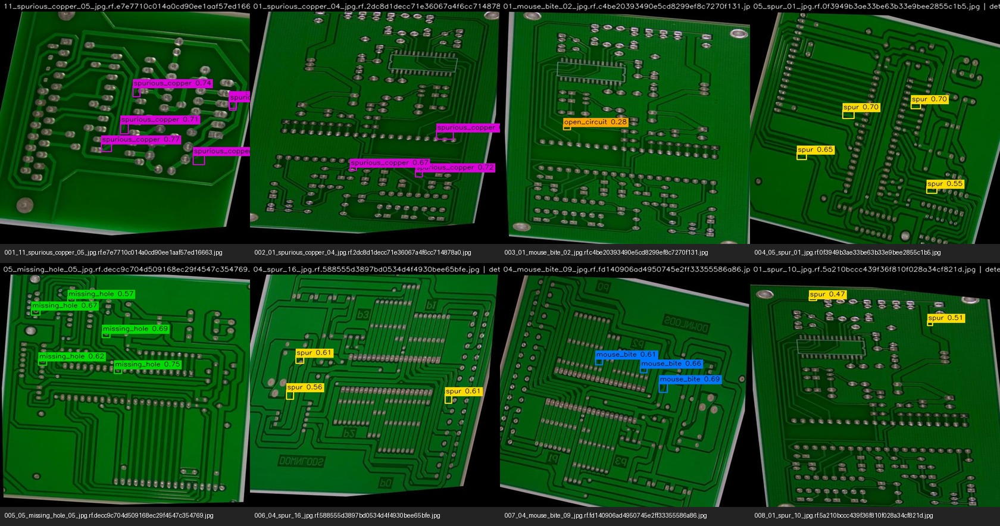

contact_sheet_02.jpg


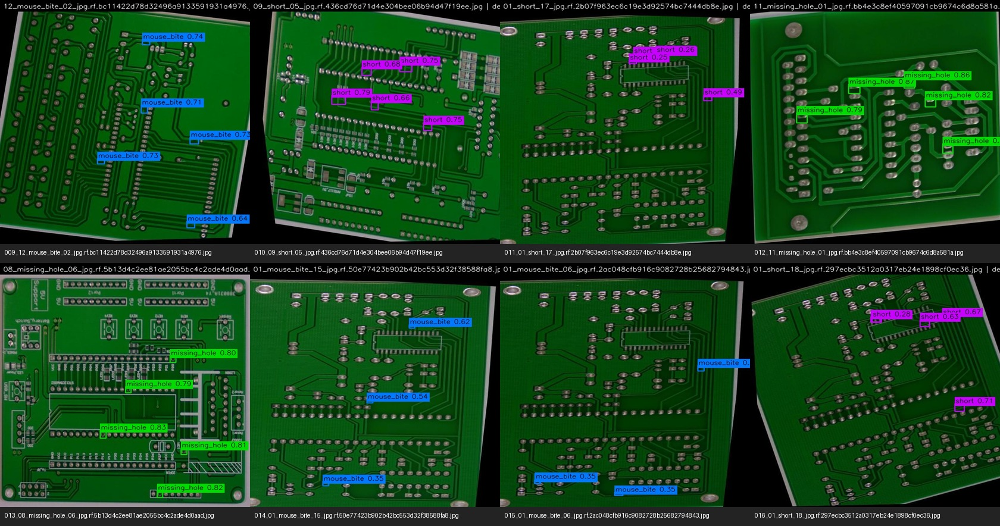

contact_sheet_03.jpg


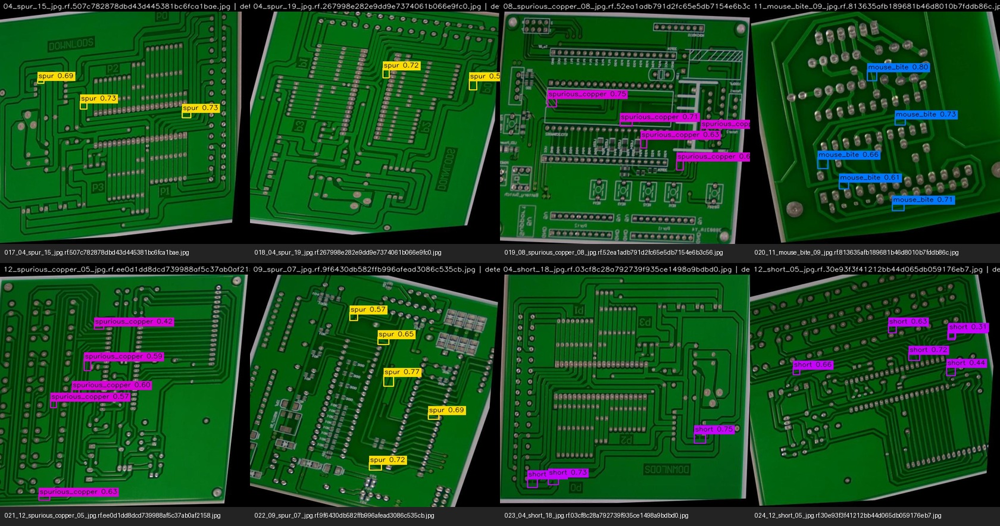

contact_sheet_04.jpg


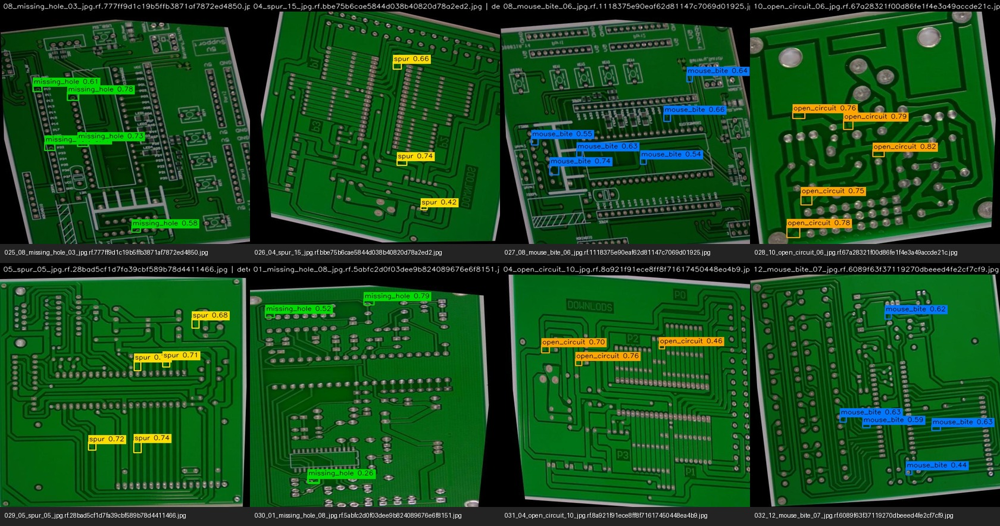

contact_sheet_05.jpg


In [ ]:
# ============================================================
# CELL 18 — RANDOM 40 TEST DETECTION VISUALIZATIONS
# Draw predictions on ORIGINAL test images
# ============================================================

from pathlib import Path
import cv2
import random
import pandas as pd
import numpy as np

from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

RAW_TEST_DIR = Path(
    "/kaggle/input/datasets/abankitabehera/pcb-defects/test/images"
)

OUTPUT_DIR = Path(
    "/kaggle/working/PCB_Defect_Submission_896"
)

PREDICTIONS_CSV = OUTPUT_DIR / "predictions.csv"

VIS_DIR = OUTPUT_DIR / "test_visualizations"
VIS_DIR.mkdir(parents=True, exist_ok=True)

SAMPLE_COUNT = 40
VIS_CONF_THRESHOLD = 0.25
RANDOM_SEED = 42

CLASS_NAMES = [
    "missing_hole",
    "mouse_bite",
    "open_circuit",
    "short",
    "spur",
    "spurious_copper"
]

# OpenCV BGR colours, one per class.
CLASS_COLORS = [
    (0, 220, 0),
    (255, 120, 0),
    (0, 165, 255),
    (255, 0, 200),
    (0, 220, 255),
    (220, 0, 220)
]

# ------------------------------------------------------------
# 2. Load complete predictions CSV
# ------------------------------------------------------------

assert PREDICTIONS_CSV.exists(), (
    "Run Cell 17 before running this cell."
)

pred_df = pd.read_csv(PREDICTIONS_CSV)

# Select images with at least one reasonably confident detection.
eligible_df = pred_df[
    pred_df["confidence"] >= VIS_CONF_THRESHOLD
]

eligible_names = sorted(
    eligible_df["image_name"].unique().tolist()
)

# Fallback if fewer than 30 examples meet the visual threshold.
if len(eligible_names) < 30:

    print(
        "Fewer than 30 images have confidence >= 0.25. "
        "Using all images with at least one detection."
    )

    eligible_names = sorted(
        pred_df["image_name"].unique().tolist()
    )

if len(eligible_names) == 0:
    raise RuntimeError(
        "No test detections are available to visualize."
    )

rng = random.Random(RANDOM_SEED)

sample_count = min(
    SAMPLE_COUNT,
    len(eligible_names)
)

selected_names = rng.sample(
    eligible_names,
    sample_count
)

print("Images with detections:", len(eligible_names))
print("Random images selected:", sample_count)

# ------------------------------------------------------------
# 3. Draw bounding boxes on original images
# ------------------------------------------------------------

manifest = []
visualized_files = []

for index, image_name in enumerate(
    selected_names,
    start=1
):

    image_path = RAW_TEST_DIR / image_name

    image = cv2.imread(str(image_path))

    if image is None:
        raise RuntimeError(
            f"Could not load original image: {image_path}"
        )

    h, w = image.shape[:2]

    image_preds = pred_df[
        pred_df["image_name"] == image_name
    ]

    # Apply display-only threshold.
    image_preds = image_preds[
        image_preds["confidence"] >= VIS_CONF_THRESHOLD
    ]

    # When fallback selected an image with low-confidence
    # detections, show its strongest prediction.
    if image_preds.empty:

        image_preds = (
            pred_df[pred_df["image_name"] == image_name]
            .nlargest(1, "confidence")
        )

    for _, row in image_preds.iterrows():

        class_name = row["class_name"]
        class_id = CLASS_NAMES.index(class_name)

        color = CLASS_COLORS[class_id]

        x1 = int(np.clip(round(row["x_min"]), 0, w - 1))
        y1 = int(np.clip(round(row["y_min"]), 0, h - 1))
        x2 = int(np.clip(round(row["x_max"]), 0, w - 1))
        y2 = int(np.clip(round(row["y_max"]), 0, h - 1))

        if x2 <= x1 or y2 <= y1:
            continue

        confidence = float(row["confidence"])

        label = f"{class_name} {confidence:.2f}"

        thickness = max(2, round(min(h, w) / 320))

        cv2.rectangle(
            image,
            (x1, y1),
            (x2, y2),
            color,
            thickness
        )

        font_scale = max(0.45, min(w, h) / 1100)

        font_thickness = max(1, thickness - 1)

        (text_w, text_h), baseline = cv2.getTextSize(
            label,
            cv2.FONT_HERSHEY_SIMPLEX,
            font_scale,
            font_thickness
        )

        text_y = max(text_h + 5, y1)

        cv2.rectangle(
            image,
            (x1, text_y - text_h - 5),
            (min(w - 1, x1 + text_w + 5), text_y + baseline),
            color,
            -1
        )

        cv2.putText(
            image,
            label,
            (x1 + 2, text_y - 2),
            cv2.FONT_HERSHEY_SIMPLEX,
            font_scale,
            (0, 0, 0),
            font_thickness,
            cv2.LINE_AA
        )

    # Add image name banner.
    banner_height = 32

    banner = np.zeros(
        (banner_height, w, 3),
        dtype=np.uint8
    )

    cv2.putText(
        banner,
        f"{image_name} | detections: {len(image_preds)}",
        (8, 23),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.60,
        (255, 255, 255),
        1,
        cv2.LINE_AA
    )

    output_image = np.vstack([banner, image])

    output_path = VIS_DIR / f"{index:03d}_{Path(image_name).stem}.jpg"

    cv2.imwrite(
        str(output_path),
        output_image,
        [cv2.IMWRITE_JPEG_QUALITY, 95]
    )

    visualized_files.append(output_path)

    manifest.append({
        "sample_number": index,
        "image_name": image_name,
        "displayed_detections": len(image_preds),
        "visualization_file": output_path.name
    })

# ------------------------------------------------------------
# 4. Save visualization manifest
# ------------------------------------------------------------

manifest_df = pd.DataFrame(manifest)

manifest_df.to_csv(
    VIS_DIR / "visualization_manifest.csv",
    index=False
)

print("\nIndividual visualizations saved:", len(visualized_files))

# ------------------------------------------------------------
# 5. Create contact sheets (8 images per sheet)
# ------------------------------------------------------------

TILE_WIDTH = 420
TILE_IMAGE_HEIGHT = 410
TILE_HEADER_HEIGHT = 32

COLUMNS = 4
ROWS = 2

TILE_HEIGHT = TILE_IMAGE_HEIGHT + TILE_HEADER_HEIGHT

font = ImageFont.load_default()

contact_sheets = []

for start in range(0, len(visualized_files), COLUMNS * ROWS):

    group = visualized_files[
        start:start + COLUMNS * ROWS
    ]

    sheet = Image.new(
        "RGB",
        (
            COLUMNS * TILE_WIDTH,
            ROWS * TILE_HEIGHT
        ),
        (35, 35, 35)
    )

    for offset, image_file in enumerate(group):

        image = Image.open(image_file).convert("RGB")

        image = image.resize(
            (TILE_WIDTH, TILE_IMAGE_HEIGHT),
            Image.Resampling.LANCZOS
        )

        tile = Image.new(
            "RGB",
            (TILE_WIDTH, TILE_HEIGHT),
            (35, 35, 35)
        )

        tile.paste(image, (0, 0))

        draw = ImageDraw.Draw(tile)

        draw.text(
            (8, TILE_IMAGE_HEIGHT + 8),
            image_file.name,
            fill=(255, 255, 255),
            font=font
        )

        row = offset // COLUMNS
        col = offset % COLUMNS

        sheet.paste(
            tile,
            (col * TILE_WIDTH, row * TILE_HEIGHT)
        )

    sheet_number = start // (COLUMNS * ROWS) + 1

    sheet_path = VIS_DIR / f"contact_sheet_{sheet_number:02d}.jpg"

    sheet.save(
        sheet_path,
        quality=92
    )

    contact_sheets.append(sheet_path)

print("Contact sheets created:", len(contact_sheets))
print("Visualization directory:", VIS_DIR)

# ------------------------------------------------------------
# 6. Display contact sheets in Kaggle
# ------------------------------------------------------------

for sheet_path in contact_sheets:

    print(sheet_path.name)

    display(
        Image.open(sheet_path)
    )

print("\nVisualization manifest:")
display(manifest_df)

In [9]:
# ============================================================
# CELL 19A — CREATE SUBMISSION SOURCE CODE AND DOCUMENTATION
# ============================================================

from pathlib import Path

PACKAGE_ROOT = Path(
    "/kaggle/working/MODEL_MAYHEM_PCB_SUBMISSION"
)

CODE_DIR = PACKAGE_ROOT / "code"
WEIGHTS_DIR = PACKAGE_ROOT / "weights"
REPORT_DIR = PACKAGE_ROOT / "validation"
VIS_DIR_PACKAGE = PACKAGE_ROOT / "test_visualizations"

for directory in [
    CODE_DIR,
    WEIGHTS_DIR,
    REPORT_DIR,
    VIS_DIR_PACKAGE
]:
    directory.mkdir(parents=True, exist_ok=True)


# ============================================================
# 1. TRAINING SCRIPT
# ============================================================

TRAIN_SCRIPT = r'''
import argparse
import shutil
from pathlib import Path

import cv2
import numpy as np
import yaml

from ultralytics import YOLO
from ultralytics.models.yolo.detect import DetectionTrainer


CLASS_NAMES = [
    "missing_hole",
    "mouse_bite",
    "open_circuit",
    "short",
    "spur",
    "spurious_copper"
]

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"
}


def preprocess_image(image):
    """Apply CLAHE to LAB luminance without changing geometry."""

    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)

    l_channel, a_channel, b_channel = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=1.5,
        tileGridSize=(8, 8)
    )

    enhanced_l = clahe.apply(l_channel)

    enhanced_lab = cv2.merge([
        enhanced_l,
        a_channel,
        b_channel
    ])

    return cv2.cvtColor(
        enhanced_lab,
        cv2.COLOR_LAB2BGR
    )


def prepare_dataset(source_root, output_root):

    source_root = Path(source_root)
    output_root = Path(output_root)

    if not source_root.exists():
        raise FileNotFoundError(source_root)

    for split in ["train", "valid", "test"]:

        source_images = source_root / split / "images"
        source_labels = source_root / split / "labels"

        output_images = output_root / split / "images"
        output_labels = output_root / split / "labels"

        output_images.mkdir(parents=True, exist_ok=True)
        output_labels.mkdir(parents=True, exist_ok=True)

        images = sorted([
            p for p in source_images.iterdir()
            if p.is_file()
            and p.suffix.lower() in IMAGE_EXTENSIONS
        ])

        labels = {
            p.stem: p
            for p in source_labels.glob("*.txt")
        }

        for image_path in images:

            if image_path.stem not in labels:
                raise FileNotFoundError(
                    f"Missing label for {image_path.name}"
                )

            image = cv2.imread(str(image_path))

            if image is None:
                raise RuntimeError(
                    f"Cannot read {image_path}"
                )

            processed = preprocess_image(image)

            destination = output_images / image_path.name

            if image_path.suffix.lower() in {".jpg", ".jpeg"}:
                success = cv2.imwrite(
                    str(destination),
                    processed,
                    [cv2.IMWRITE_JPEG_QUALITY, 95]
                )
            else:
                success = cv2.imwrite(
                    str(destination),
                    processed
                )

            if not success:
                raise RuntimeError(
                    f"Cannot save {destination}"
                )

        for label_path in labels.values():
            shutil.copy2(
                label_path,
                output_labels / label_path.name
            )

        print(
            f"{split}: {len(images)} images prepared"
        )

    data_yaml = output_root / "data.yaml"

    config = {
        "path": str(output_root),
        "train": "train/images",
        "val": "valid/images",
        "test": "test/images",
        "nc": 6,
        "names": CLASS_NAMES
    }

    data_yaml.write_text(
        yaml.safe_dump(config, sort_keys=False)
    )

    return data_yaml


class PCBCompetitionTrainer(DetectionTrainer):

    def validate(self):

        previous_best = self.best_fitness

        metrics, fitness = super().validate()

        if metrics is None:
            return metrics, fitness

        all_ap = np.asarray(
            self.validator.metrics.box.all_ap,
            dtype=np.float64
        )

        class_ids = np.asarray(
            self.validator.metrics.box.ap_class_index,
            dtype=int
        )

        if all_ap.shape != (6, 10):
            raise RuntimeError(
                f"Unexpected AP matrix shape: {all_ap.shape}"
            )

        if set(class_ids.tolist()) != set(range(6)):
            raise RuntimeError(
                "Validation must contain all six classes."
            )

        ap_by_class = np.full(
            (6, 10),
            np.nan,
            dtype=np.float64
        )

        for row, class_id in enumerate(class_ids):
            ap_by_class[class_id] = all_ap[row]

        competition_map = float(
            ap_by_class[:, :9].mean()
        )

        if not np.isfinite(competition_map):
            raise RuntimeError(
                "Invalid competition mAP@50:90."
            )

        metrics["metrics/mAP50-90(B)"] = competition_map

        fitness = competition_map

        self.best_fitness = (
            fitness if previous_best is None
            else max(float(previous_best), fitness)
        )

        print(
            f"Competition mAP@50:90: {competition_map:.6f}"
        )

        return metrics, fitness


def main():

    parser = argparse.ArgumentParser()

    parser.add_argument(
        "--dataset-root",
        default="/kaggle/input/datasets/abankitabehera/pcb-defects"
    )

    parser.add_argument(
        "--preprocessed-root",
        default="./pcb_defects_clahe"
    )

    parser.add_argument(
        "--weights",
        default="yolo26m.pt"
    )

    parser.add_argument(
        "--project",
        default="./pcb_runs"
    )

    parser.add_argument(
        "--device",
        default="0,1"
    )

    args = parser.parse_args()

    data_yaml = prepare_dataset(
        args.dataset_root,
        args.preprocessed_root
    )

    if "," in args.device:
        device = [
            int(x.strip())
            for x in args.device.split(",")
        ]
    else:
        device = int(args.device)

    model = YOLO(args.weights)

    model.train(
        data=str(data_yaml),

        imgsz=896,
        epochs=120,
        patience=30,
        batch=8,
        device=device,
        workers=2,

        optimizer="AdamW",
        lr0=0.001,
        lrf=0.01,
        momentum=0.937,
        weight_decay=0.0005,
        warmup_epochs=2,
        cos_lr=True,

        hsv_h=0.005,
        hsv_s=0.08,
        hsv_v=0.12,

        degrees=0.0,
        translate=0.03,
        scale=0.10,

        fliplr=0.5,
        flipud=0.5,

        mosaic=0.10,
        close_mosaic=10,
        mixup=0.0,
        copy_paste=0.0,

        augmentations=[],
        cls_pw=0.0,

        amp=True,
        cache=False,
        multi_scale=False,

        save=True,
        save_period=5,
        plots=True,
        val=True,

        project=args.project,
        name="YOLO26m_896_CLAHE_Competition",
        exist_ok=False,

        resume=False,
        seed=42,
        deterministic=True,

        trainer=PCBCompetitionTrainer
    )


if __name__ == "__main__":
    main()
'''

(CODE_DIR / "train.py").write_text(TRAIN_SCRIPT)


# ============================================================
# 2. INFERENCE SCRIPT
# ============================================================

INFERENCE_SCRIPT = r'''
import argparse
from pathlib import Path

import cv2
import numpy as np
import pandas as pd

from ultralytics import YOLO


CLASS_NAMES = [
    "missing_hole",
    "mouse_bite",
    "open_circuit",
    "short",
    "spur",
    "spurious_copper"
]

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"
}


def preprocess_image(image):

    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)

    l_channel, a_channel, b_channel = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=1.5,
        tileGridSize=(8, 8)
    )

    enhanced_l = clahe.apply(l_channel)

    enhanced_lab = cv2.merge([
        enhanced_l,
        a_channel,
        b_channel
    ])

    return cv2.cvtColor(
        enhanced_lab,
        cv2.COLOR_LAB2BGR
    )


def main():

    parser = argparse.ArgumentParser()

    parser.add_argument("--weights", required=True)
    parser.add_argument("--source", required=True)
    parser.add_argument(
        "--output",
        default="predictions.csv"
    )

    parser.add_argument("--imgsz", type=int, default=896)
    parser.add_argument("--conf", type=float, default=0.001)
    parser.add_argument("--iou", type=float, default=0.70)
    parser.add_argument("--max-det", type=int, default=300)
    parser.add_argument("--device", default="0")

    args = parser.parse_args()

    source = Path(args.source)

    image_paths = sorted([
        p for p in source.iterdir()
        if p.is_file()
        and p.suffix.lower() in IMAGE_EXTENSIONS
    ])

    if not image_paths:
        raise FileNotFoundError(
            f"No supported images found in {source}"
        )

    model = YOLO(args.weights)

    rows = []

    for image_path in image_paths:

        image = cv2.imread(str(image_path))

        if image is None:
            raise RuntimeError(
                f"Cannot read {image_path}"
            )

        height, width = image.shape[:2]

        processed = preprocess_image(image)

        result = model.predict(
            source=processed,
            imgsz=args.imgsz,
            conf=args.conf,
            iou=args.iou,
            max_det=args.max_det,
            device=args.device,
            agnostic_nms=False,
            save=False,
            verbose=False
        )[0]

        if result.boxes is None:
            continue

        boxes = result.boxes.xyxy.cpu().numpy()
        confidences = result.boxes.conf.cpu().numpy()
        class_ids = result.boxes.cls.cpu().numpy().astype(int)

        for box, confidence, class_id in zip(
            boxes,
            confidences,
            class_ids
        ):

            if class_id < 0 or class_id >= len(CLASS_NAMES):
                raise ValueError(
                    f"Invalid class ID: {class_id}"
                )

            x1, y1, x2, y2 = map(float, box)

            x1 = float(np.clip(x1, 0, width))
            x2 = float(np.clip(x2, 0, width))
            y1 = float(np.clip(y1, 0, height))
            y2 = float(np.clip(y2, 0, height))

            if x2 <= x1 or y2 <= y1:
                continue

            rows.append({
                "image_name": image_path.name,
                "class_name": CLASS_NAMES[class_id],
                "x_min": round(x1, 2),
                "y_min": round(y1, 2),
                "x_max": round(x2, 2),
                "y_max": round(y2, 2),
                "confidence": round(float(confidence), 6)
            })

    columns = [
        "image_name",
        "class_name",
        "x_min",
        "y_min",
        "x_max",
        "y_max",
        "confidence"
    ]

    output = Path(args.output)
    output.parent.mkdir(parents=True, exist_ok=True)

    pd.DataFrame(
        rows,
        columns=columns
    ).to_csv(output, index=False)

    print("Images processed:", len(image_paths))
    print("Detections:", len(rows))
    print("Predictions saved:", output)


if __name__ == "__main__":
    main()
'''

(CODE_DIR / "inference.py").write_text(INFERENCE_SCRIPT)


# ============================================================
# 3. REQUIREMENTS
# ============================================================

REQUIREMENTS = """
ultralytics==8.4.210
numpy
opencv-python-headless
pandas
PyYAML
Pillow
matplotlib
tqdm
"""

(PACKAGE_ROOT / "requirements.txt").write_text(
    REQUIREMENTS.strip() + "\n"
)


# ============================================================
# 4. README
# ============================================================


README = r"""
# MODEL MAYHEM — PCB Defect Detection

## 1. Model Overview

- Architecture: YOLO26m
- Task: Six-class PCB defect object detection
- Input resolution: 896 x 896
- Preprocessing: CLAHE applied to the LAB luminance channel
- Optimizer: AdamW
- Initial learning rate: 0.001
- Maximum training epochs: 120
- Early-stopping patience: 30
- Checkpoint-selection metric: Competition mAP@50:90

The final model was fine-tuned from the official pretrained
`yolo26m.pt` checkpoint.

The previous 640-resolution training checkpoint was unavailable
in the training kernel. Therefore, this run was a fresh
transfer-learning run, not a continuation of the previous run.

## 2. Target Classes

The class IDs must remain in this exact order:

| Class ID | Class Name |
|---|---|
| 0 | missing_hole |
| 1 | mouse_bite |
| 2 | open_circuit |
| 3 | short |
| 4 | spur |
| 5 | spurious_copper |

## 3. Submission Files

- `weights/best.pt` — final trained inference checkpoint
- `code/train.py` — dataset preprocessing and model training
- `code/inference.py` — inference and CSV-generation script
- `predictions.csv` — predictions in the prescribed format
- `requirements.txt` — Python dependencies
- `validation/` — validation metrics and training history
- `test_visualizations/` — test prediction images and contact sheets

## 4. Recorded Training Environment

- Python: 3.13.16
- Ultralytics: 8.4.210
- PyTorch: 2.11.0+cu130
- Hardware: 2 x NVIDIA Tesla T4

Install PyTorch separately using a version compatible with your
target CUDA environment before installing the remaining packages.

Install the remaining dependencies:

```bash
pip install -r requirements.txt
```

## 5. Dataset Structure

The training script expects the following dataset structure:

```text
pcb-defects/
    train/
        images/
        labels/
    valid/
        images/
        labels/
    test/
        images/
        labels/
```

The labels must use YOLO detection format:

```text
class_id x_center y_center width height
```

Coordinates must be normalized to the range 0 to 1.

## 6. Training Instructions

Run training from the submission root directory.

Example for a machine with two available GPUs:

```bash
python code/train.py \
    --dataset-root /path/to/pcb-defects \
    --preprocessed-root ./pcb_defects_clahe \
    --weights yolo26m.pt \
    --project ./pcb_runs \
    --device 0,1
```

For a machine with one GPU:

```bash
python code/train.py \
    --dataset-root /path/to/pcb-defects \
    --weights yolo26m.pt \
    --project ./pcb_runs \
    --device 0
```

Training uses CLAHE preprocessing, 896-pixel input resolution,
AdamW optimization, and the competition-specific mAP@50:90
checkpoint-selection metric.

## 7. Inference Instructions

Place the test images in a directory and run:

```bash
python code/inference.py \
    --weights weights/best.pt \
    --source /path/to/test/images \
    --output predictions.csv \
    --imgsz 896 \
    --conf 0.001 \
    --iou 0.70 \
    --max-det 300 \
    --device cpu
```

The inference script applies the same CLAHE preprocessing used
during training and runs detection on each image.

Use `--device 0` instead of `--device cpu` when GPU inference
is available and sufficient GPU memory is available.

## 8. Prediction CSV Format

The output CSV contains exactly these columns:

```text
image_name,class_name,x_min,y_min,x_max,y_max,confidence
```

Each row represents one predicted bounding box.

- `image_name`: Original image filename
- `class_name`: Predicted PCB defect class
- `x_min`, `y_min`: Top-left bounding-box coordinates
- `x_max`, `y_max`: Bottom-right bounding-box coordinates
- `confidence`: Prediction confidence between 0 and 1

Bounding-box coordinates are expressed in original image pixels.

## 9. Reproducibility

The training configuration, validation metrics, training history,
inference configuration, and generated prediction visualizations
are included where available in the submission package.

The final inference checkpoint is `weights/best.pt`.
"""

# Save README
README_PATH = PACKAGE_ROOT / "README.md"

README_PATH.write_text(
    README.strip() + "\n",
    encoding="utf-8"
)

print("Cell 19A source-code and documentation generation completed.")

print("\nGenerated files:")
for file_path in sorted(PACKAGE_ROOT.rglob("*")):
    if file_path.is_file():
        print("  ", file_path.relative_to(PACKAGE_ROOT))


Cell 19A source-code and documentation generation completed.

Generated files:
   README.md
   code/inference.py
   code/train.py
   requirements.txt


In [10]:

# ============================================================
# CELL 19B — BUILD AND VERIFY FINAL MODEL MAYHEM SUBMISSION ZIP
# ============================================================

from pathlib import Path
import shutil
import zipfile
import hashlib
import json
import yaml
import csv


# ------------------------------------------------------------
# 1. MAIN PATHS
# ------------------------------------------------------------

RUN_DIR = Path(
    "/kaggle/working/pcb_runs_896/"
    "YOLO26m_896_CLAHE_Competition"
)

OUTPUT_DIR = Path(
    "/kaggle/working/PCB_Defect_Submission_896"
)

PACKAGE_ROOT = Path(
    "/kaggle/working/MODEL_MAYHEM_PCB_SUBMISSION"
)

ZIP_PATH = Path(
    "/kaggle/working/MODEL_MAYHEM_PCB_Submission.zip"
)

BEST_MODEL = RUN_DIR / "weights" / "best.pt"
RESULTS_CSV = RUN_DIR / "results.csv"
ARGS_YAML = RUN_DIR / "args.yaml"


# ------------------------------------------------------------
# 2. VERIFY INPUTS BEFORE MODIFYING PACKAGE
# ------------------------------------------------------------

required_inputs = [
    BEST_MODEL,
    RESULTS_CSV,
    ARGS_YAML,

    OUTPUT_DIR / "predictions.csv",
    OUTPUT_DIR / "test_image_summary.csv",
    OUTPUT_DIR / "inference_config.json",

    OUTPUT_DIR / "validation_metrics.json",
    OUTPUT_DIR / "per_class_metrics.csv",
    OUTPUT_DIR / "per_iou_metrics.csv",

    OUTPUT_DIR / "test_visualizations" /
    "visualization_manifest.csv",

    PACKAGE_ROOT / "code" / "train.py",
    PACKAGE_ROOT / "code" / "inference.py",
    PACKAGE_ROOT / "requirements.txt",
    PACKAGE_ROOT / "README.md"
]

missing_inputs = [
    str(path)
    for path in required_inputs
    if not path.is_file()
]

if missing_inputs:
    raise FileNotFoundError(
        "Required input files are missing.\n"
        "Run the corresponding earlier cells first:\n\n"
        + "\n".join(missing_inputs)
    )

if BEST_MODEL.stat().st_size == 0:
    raise RuntimeError("The best.pt checkpoint is empty.")


# ------------------------------------------------------------
# 3. VERIFY PREDICTION CSV FORMAT
# ------------------------------------------------------------

PREDICTION_COLUMNS = [
    "image_name",
    "class_name",
    "x_min",
    "y_min",
    "x_max",
    "y_max",
    "confidence"
]

with open(OUTPUT_DIR / "predictions.csv", "r", newline="") as f:
    reader = csv.reader(f)
    actual_columns = next(reader, None)

if actual_columns != PREDICTION_COLUMNS:
    raise ValueError(
        "Predictions CSV has an incorrect header.\n"
        f"Expected: {PREDICTION_COLUMNS}\n"
        f"Received: {actual_columns}"
    )

print("Prediction CSV header verified.")


# ------------------------------------------------------------
# 4. PREPARE PACKAGE DIRECTORIES
# ------------------------------------------------------------

# IMPORTANT:
# Do NOT delete PACKAGE_ROOT.
# Cell 19A already generated train.py, inference.py,
# README.md and requirements.txt inside this directory.

# Rebuild only the folders that contain copied artifacts.

for folder_name in [
    "weights",
    "validation",
    "test_visualizations"
]:

    folder_path = PACKAGE_ROOT / folder_name

    if folder_path.exists():
        shutil.rmtree(folder_path)

    folder_path.mkdir(parents=True, exist_ok=True)


# Remove old copied prediction files to prevent stale outputs.

for filename in [
    "predictions.csv",
    "test_image_summary.csv",
    "inference_config.json",
    "PROVENANCE.txt",
    "SHA256SUMS.txt"
]:

    file_path = PACKAGE_ROOT / filename

    if file_path.exists():
        file_path.unlink()


print("Package directories prepared.")
print("Cell 19A source files preserved.")


# ------------------------------------------------------------
# 5. COPY FINAL MODEL WEIGHTS
# ------------------------------------------------------------

shutil.copy2(
    BEST_MODEL,
    PACKAGE_ROOT / "weights" / "best.pt"
)

print(
    "Final model copied:",
    round(BEST_MODEL.stat().st_size / 1024**2, 2),
    "MB"
)


# ------------------------------------------------------------
# 6. COPY TEST PREDICTIONS
# ------------------------------------------------------------

for filename in [
    "predictions.csv",
    "test_image_summary.csv",
    "inference_config.json"
]:

    shutil.copy2(
        OUTPUT_DIR / filename,
        PACKAGE_ROOT / filename
    )

print("Test prediction files copied.")


# ------------------------------------------------------------
# 7. COPY VALIDATION METRICS
# ------------------------------------------------------------

for filename in [
    "validation_metrics.json",
    "per_class_metrics.csv",
    "per_iou_metrics.csv"
]:

    shutil.copy2(
        OUTPUT_DIR / filename,
        PACKAGE_ROOT / "validation" / filename
    )

print("Validation metrics copied.")


# ------------------------------------------------------------
# 8. COPY ACTUAL TRAINING HISTORY AND CONFIGURATION
# ------------------------------------------------------------

shutil.copy2(
    RESULTS_CSV,
    PACKAGE_ROOT / "validation" / "training_history.csv"
)

shutil.copy2(
    ARGS_YAML,
    PACKAGE_ROOT / "validation" / "args.yaml"
)


# Read actual Ultralytics training arguments.

with open(ARGS_YAML, "r") as f:
    actual_args = yaml.safe_load(f)

if not isinstance(actual_args, dict):
    raise ValueError("Could not read valid training arguments from args.yaml.")


training_metadata = {
    "architecture": "YOLO26m",

    "starting_weights": actual_args.get("model"),

    "training_mode": (
        "Fresh transfer learning from pretrained yolo26m.pt"
    ),

    "image_size": actual_args.get("imgsz"),
    "batch_size": actual_args.get("batch"),

    "epochs_configured": actual_args.get("epochs"),
    "optimizer": actual_args.get("optimizer"),

    "learning_rate": actual_args.get("lr0"),
    "final_lr_factor": actual_args.get("lrf"),

    "momentum": actual_args.get("momentum"),
    "weight_decay": actual_args.get("weight_decay"),

    "warmup_epochs": actual_args.get("warmup_epochs"),
    "cosine_lr": actual_args.get("cos_lr"),

    "patience": actual_args.get("patience"),

    "box_loss_gain": actual_args.get("box"),
    "classification_loss_gain": actual_args.get("cls"),

    "regression_loss_setting": actual_args.get("dfl"),

    "class_weight": actual_args.get("cls_pw"),

    "mosaic": actual_args.get("mosaic"),
    "mixup": actual_args.get("mixup"),

    "clahe": {
        "enabled": True,
        "color_space": "LAB",
        "channel": "L",
        "clip_limit": 1.5,
        "tile_grid_size": [8, 8]
    },

    "competition_metric": "mAP@50:90",
    "checkpoint_selection_metric": "mAP@50:90",

    "class_names": [
        "missing_hole",
        "mouse_bite",
        "open_circuit",
        "short",
        "spur",
        "spurious_copper"
    ],

    "ultralytics_version": "8.4.210"
}


(PACKAGE_ROOT / "validation" / "training_config.json").write_text(
    json.dumps(training_metadata, indent=4),
    encoding="utf-8"
)

print("Actual training configuration saved.")


# ------------------------------------------------------------
# 9. VERIFY CELL 19A SOURCE FILES
# ------------------------------------------------------------

source_files = [
    PACKAGE_ROOT / "code" / "train.py",
    PACKAGE_ROOT / "code" / "inference.py",
    PACKAGE_ROOT / "requirements.txt",
    PACKAGE_ROOT / "README.md"
]

for source_file in source_files:

    if not source_file.is_file() or source_file.stat().st_size == 0:
        raise RuntimeError(
            f"Source file missing or empty: {source_file}"
        )

print("Training code, inference code, dependencies and README verified.")


# ------------------------------------------------------------
# 10. COPY TEST VISUALIZATIONS
# ------------------------------------------------------------

SOURCE_VIS_DIR = OUTPUT_DIR / "test_visualizations"
DEST_VIS_DIR = PACKAGE_ROOT / "test_visualizations"

shutil.copytree(
    SOURCE_VIS_DIR,
    DEST_VIS_DIR,
    dirs_exist_ok=True
)

print(
    "Test visualizations copied:",
    sum(1 for p in DEST_VIS_DIR.rglob("*") if p.is_file()),
    "files"
)


# ------------------------------------------------------------
# 11. COPY TRAINING PLOTS
# ------------------------------------------------------------

plot_files = [
    "results.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "BoxPR_curve.png",
    "BoxP_curve.png",
    "BoxR_curve.png",
    "BoxF1_curve.png"
]

for filename in plot_files:

    source = RUN_DIR / filename

    if source.is_file():

        shutil.copy2(
            source,
            PACKAGE_ROOT / "validation" / filename
        )


# ------------------------------------------------------------
# 12. RECORD TRAINING PROVENANCE
# ------------------------------------------------------------

provenance = """
MODEL MAYHEM — PCB DEFECT DETECTION

Final model: YOLO26m
Input resolution: 896 x 896

Preprocessing:
CLAHE on LAB luminance channel
Clip limit: 1.5
Tile grid size: 8 x 8

Starting weights: yolo26m.pt
Training approach: Fresh transfer learning

The previous 640-resolution checkpoint was not available
in the training kernel. This run was not resumed from it.

Validation set:
517 images
2218 annotated instances

Competition evaluation metric:
mAP@50:90

Test predictions:
Generated from the supplied local test image directory.

The test labels were not used for model training or inference.

The organiser-held-out test score is not known from this package.
"""

(PACKAGE_ROOT / "PROVENANCE.txt").write_text(
    provenance.strip() + "\n",
    encoding="utf-8"
)


# ------------------------------------------------------------
# 13. CREATE SHA256 CHECKSUM FOR MODEL WEIGHTS
# ------------------------------------------------------------

weight_path = PACKAGE_ROOT / "weights" / "best.pt"

sha256 = hashlib.sha256()

with open(weight_path, "rb") as f:

    for chunk in iter(
        lambda: f.read(1024 * 1024),
        b""
    ):
        sha256.update(chunk)

(PACKAGE_ROOT / "SHA256SUMS.txt").write_text(
    f"{sha256.hexdigest()}  weights/best.pt\n",
    encoding="utf-8"
)

print("Model SHA256 checksum generated.")


# ------------------------------------------------------------
# 14. VERIFY ALL REQUIRED SUBMISSION FILES
# ------------------------------------------------------------

required_files = [

    # Main documentation
    "README.md",
    "requirements.txt",
    "PROVENANCE.txt",
    "SHA256SUMS.txt",

    # Source code
    "code/train.py",
    "code/inference.py",

    # Trained weights
    "weights/best.pt",

    # Predictions
    "predictions.csv",
    "test_image_summary.csv",
    "inference_config.json",

    # Validation
    "validation/validation_metrics.json",
    "validation/per_class_metrics.csv",
    "validation/per_iou_metrics.csv",
    "validation/training_history.csv",
    "validation/args.yaml",
    "validation/training_config.json",

    # Visualizations
    "test_visualizations/visualization_manifest.csv"
]

missing = [
    filename
    for filename in required_files
    if not (PACKAGE_ROOT / filename).is_file()
]

if missing:

    raise FileNotFoundError(
        "Submission package is incomplete.\nMissing files:\n"
        + "\n".join(missing)
    )

print("All required submission files verified.")


# ------------------------------------------------------------
# 15. BUILD FINAL SUBMISSION ZIP
# ------------------------------------------------------------

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=1
) as archive:

    for file in sorted(PACKAGE_ROOT.rglob("*")):

        if file.is_file():

            archive.write(
                file,
                arcname=str(file.relative_to(PACKAGE_ROOT))
            )

print("Submission ZIP created.")


# ------------------------------------------------------------
# 16. VERIFY ZIP CONTENTS AND INTEGRITY
# ------------------------------------------------------------

with zipfile.ZipFile(ZIP_PATH, "r") as archive:

    bad_file = archive.testzip()

    if bad_file is not None:
        raise RuntimeError(
            f"ZIP integrity check failed: {bad_file}"
        )

    archived_names = set(archive.namelist())

    missing_in_zip = [
        filename
        for filename in required_files
        if filename not in archived_names
    ]

    if missing_in_zip:
        raise RuntimeError(
            "Files missing from ZIP:\n"
            + "\n".join(missing_in_zip)
        )

    print("\nFINAL SUBMISSION ARCHIVE CONTENTS")

    for filename in sorted(archived_names):
        print(filename)


# ------------------------------------------------------------
# 17. FINAL REPORT
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("MODEL MAYHEM SUBMISSION PACKAGE CREATED SUCCESSFULLY")
print("=" * 65)

print("\nPackage directory:")
print(PACKAGE_ROOT)

print("\nZIP file:")
print(ZIP_PATH)

print(
    "\nZIP size:",
    round(ZIP_PATH.stat().st_size / 1024**2, 2),
    "MB"
)

print(
    "Files included:",
    len(archived_names)
)

print(
    "Required files verified:",
    len(required_files)
)

print("\nSubmission package verification: PASSED")


Prediction CSV header verified.
Package directories prepared.
Cell 19A source files preserved.
Final model copied: 42.06 MB
Test prediction files copied.
Validation metrics copied.
Actual training configuration saved.
Training code, inference code, dependencies and README verified.
Test visualizations copied: 46 files
Model SHA256 checksum generated.
All required submission files verified.
Submission ZIP created.

FINAL SUBMISSION ARCHIVE CONTENTS
PROVENANCE.txt
README.md
SHA256SUMS.txt
code/inference.py
code/train.py
inference_config.json
predictions.csv
requirements.txt
test_image_summary.csv
test_visualizations/001_11_spurious_copper_05_jpg.rf.e7e7710c014a0cd90ee1aaf57ed16663.jpg
test_visualizations/002_01_spurious_copper_04_jpg.rf.2dc8d1decc71e36067a4f6cc714878a0.jpg
test_visualizations/003_01_mouse_bite_02_jpg.rf.c4be20393490e5cd8299ef8c7270f131.jpg
test_visualizations/004_05_spur_01_jpg.rf.0f3949b3ae33be63b33e9bee2855c1b5.jpg
test_visualizations/005_05_missing_hole_05_jpg.rf.decc

In [11]:

# ============================================================
# CELL 20 — FINAL TEST SET EVALUATION
# YOLO26m | 896 IMG SIZE | CLAHE
# ============================================================

from pathlib import Path
import shutil
import yaml
import json
import numpy as np
import pandas as pd
import torch

from ultralytics import YOLO


# ------------------------------------------------------------
# 1. PATHS AND CONFIGURATION
# ------------------------------------------------------------

BEST_MODEL = Path(
    "/kaggle/working/pcb_runs_896/"
    "YOLO26m_896_CLAHE_Competition/weights/best.pt"
)

RAW_ROOT = Path(
    "/kaggle/input/datasets/abankitabehera/pcb-defects"
)

PREPROCESSED_ROOT = Path(
    "/kaggle/working/pcb_defects_clahe_v1"
)

TEST_IMAGES = PREPROCESSED_ROOT / "test" / "images"
TEST_LABELS = PREPROCESSED_ROOT / "test" / "labels"

RAW_TEST_LABELS = RAW_ROOT / "test" / "labels"

EVAL_DIR = Path(
    "/kaggle/working/PCB_Test_Evaluation"
)

EVAL_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    "missing_hole",
    "mouse_bite",
    "open_circuit",
    "short",
    "spur",
    "spurious_copper"
]

IMG_SIZE = 896

# Conservative evaluation to avoid CUDA memory issues.
DEVICE = "cpu"

# ------------------------------------------------------------
# 2. VERIFY MODEL AND TEST DATA
# ------------------------------------------------------------

assert BEST_MODEL.exists(), (
    f"Model checkpoint not found: {BEST_MODEL}"
)

assert TEST_IMAGES.exists(), (
    f"CLAHE test images not found: {TEST_IMAGES}"
)

test_images = [
    p for p in TEST_IMAGES.iterdir()
    if p.is_file()
    and p.suffix.lower() in [
        ".jpg", ".jpeg", ".png", ".bmp",
        ".tif", ".tiff"
    ]
]

assert len(test_images) > 0, "No test images found."

print("Test images:", len(test_images))


# ------------------------------------------------------------
# 3. ENSURE TEST LABELS ARE AVAILABLE
# ------------------------------------------------------------

TEST_LABELS.mkdir(parents=True, exist_ok=True)

if not RAW_TEST_LABELS.exists():
    raise FileNotFoundError(
        "Original test labels are unavailable. "
        "Cannot calculate test-set mAP without ground truth."
    )

# Copy original YOLO labels if the CLAHE folder is missing them.
for label_file in RAW_TEST_LABELS.glob("*.txt"):

    destination = TEST_LABELS / label_file.name

    if not destination.exists():
        shutil.copy2(label_file, destination)


missing_labels = [
    image.stem
    for image in test_images
    if not (TEST_LABELS / f"{image.stem}.txt").exists()
]

if missing_labels:
    raise RuntimeError(
        f"{len(missing_labels)} test images have no labels. "
        f"Examples: {missing_labels[:10]}"
    )

print("Test labels verified.")
print("Label files:", len(list(TEST_LABELS.glob("*.txt"))))


# ------------------------------------------------------------
# 4. CREATE TEST DATASET YAML
# ------------------------------------------------------------

DATA_YAML = EVAL_DIR / "test_data.yaml"

data_config = {
    "path": str(PREPROCESSED_ROOT),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 6,
    "names": CLASS_NAMES
}

with open(DATA_YAML, "w") as f:
    yaml.safe_dump(data_config, f, sort_keys=False)

print("Evaluation YAML:", DATA_YAML)


# ------------------------------------------------------------
# 5. LOAD FINAL MODEL
# ------------------------------------------------------------

print("\nLoading YOLO26m best.pt...")

model = YOLO(str(BEST_MODEL))

print("Model loaded successfully.")
print("Evaluation device:", DEVICE)


# ------------------------------------------------------------
# 6. RUN EVALUATION ON TEST SPLIT
# ------------------------------------------------------------

print("\nStarting test-set evaluation...")

test_metrics = model.val(
    data=str(DATA_YAML),

    split="test",

    imgsz=IMG_SIZE,
    batch=1,
    device=DEVICE,
    workers=0,

    conf=0.001,
    iou=0.70,
    max_det=300,

    plots=True,
    save_json=False,
    verbose=True,

    project=str(EVAL_DIR),
    name="YOLO26m_896_Test_Evaluation",
    exist_ok=True
)

print("\nTest evaluation completed.")


# ------------------------------------------------------------
# 7. EXTRACT OVERALL METRICS
# ------------------------------------------------------------

box_metrics = test_metrics.box

precision = float(box_metrics.mp)
recall = float(box_metrics.mr)

map50 = float(box_metrics.map50)
map50_95 = float(box_metrics.map)

all_ap = np.asarray(
    box_metrics.all_ap,
    dtype=np.float64
)

class_ids = np.asarray(
    box_metrics.ap_class_index,
    dtype=int
)

if all_ap.ndim != 2 or all_ap.shape[1] < 10:
    raise RuntimeError(
        f"Unexpected AP matrix shape: {all_ap.shape}"
    )

# Ultralytics AP thresholds:
# 0.50, 0.55, 0.60, 0.65, 0.70,
# 0.75, 0.80, 0.85, 0.90, 0.95

ap_by_class = np.full(
    (6, 10),
    np.nan,
    dtype=np.float64
)

for row, class_id in enumerate(class_ids):

    if 0 <= class_id < 6:
        ap_by_class[class_id] = all_ap[row]


# Competition metric uses IoU 0.50 through 0.90.
per_class_map50_90 = np.nanmean(
    ap_by_class[:, :9],
    axis=1
)

available_classes = np.isfinite(
    per_class_map50_90
)

if available_classes.all():

    competition_map = float(
        per_class_map50_90.mean()
    )

else:

    competition_map = None

    print(
        "\nWARNING: Not all six classes are represented "
        "in the test ground truth."
    )

    print(
        "An exact six-class competition mAP@50:90 "
        "cannot be reported from this split."
    )


# ------------------------------------------------------------
# 8. DISPLAY OVERALL RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("FINAL YOLO26m TEST SET RESULTS")
print("=" * 65)

print(f"Precision          : {precision:.6f}")
print(f"Recall             : {recall:.6f}")
print(f"mAP@50             : {map50:.6f}")
print(f"mAP@50:95          : {map50_95:.6f}")

if competition_map is not None:
    print(
        f"COMPETITION mAP@50:90 : {competition_map:.6f}"
    )
else:
    print("COMPETITION mAP@50:90 : Not computable for all six classes")


# ------------------------------------------------------------
# 9. PER-CLASS RESULTS
# ------------------------------------------------------------

class_rows = []

for class_id, class_name in enumerate(CLASS_NAMES):

    row = {
        "class_id": class_id,
        "class_name": class_name
    }

    for iou_index in range(10):

        threshold = 0.50 + (0.05 * iou_index)

        ap_value = ap_by_class[class_id, iou_index]

        row[f"AP{int(round(threshold * 100))}"] = (
            float(ap_value)
            if np.isfinite(ap_value)
            else np.nan
        )

    row["mAP50_90"] = (
        float(per_class_map50_90[class_id])
        if np.isfinite(per_class_map50_90[class_id])
        else np.nan
    )

    class_rows.append(row)


per_class_df = pd.DataFrame(class_rows)

print("\nPER-CLASS TEST RESULTS")

display(
    per_class_df.round(5)
)

per_class_df.to_csv(
    EVAL_DIR / "test_per_class_metrics.csv",
    index=False
)


# ------------------------------------------------------------
# 10. PER-IOU RESULTS
# ------------------------------------------------------------

iou_rows = []

for iou_index in range(10):

    threshold = 0.50 + (0.05 * iou_index)

    values = ap_by_class[:, iou_index]

    mean_ap = (
        float(np.nanmean(values))
        if np.isfinite(values).any()
        else None
    )

    iou_rows.append({
        "IoU_threshold": round(threshold, 2),
        "mean_AP": mean_ap
    })


per_iou_df = pd.DataFrame(iou_rows)

print("\nAP AT EACH IOU THRESHOLD")

display(per_iou_df.round(5))

per_iou_df.to_csv(
    EVAL_DIR / "test_per_iou_metrics.csv",
    index=False
)


# ------------------------------------------------------------
# 11. SAVE FINAL TEST METRICS
# ------------------------------------------------------------

summary = {
    "model": "YOLO26m",
    "checkpoint": str(BEST_MODEL),
    "image_size": IMG_SIZE,
    "evaluation_split": "test",
    "test_images": len(test_images),
    "device": DEVICE,

    "precision": precision,
    "recall": recall,

    "mAP50": map50,
    "mAP50_95": map50_95,

    "mAP50_90": competition_map,

    "classes_present": [
        CLASS_NAMES[i]
        for i in range(6)
        if available_classes[i]
    ],

    "class_names": CLASS_NAMES
}

with open(
    EVAL_DIR / "test_metrics.json",
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=4,
        allow_nan=False
    )


# ------------------------------------------------------------
# 12. FINAL REPORT
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("TEST EVALUATION FILES SAVED")
print("=" * 65)

print(EVAL_DIR / "test_metrics.json")
print(EVAL_DIR / "test_per_class_metrics.csv")
print(EVAL_DIR / "test_per_iou_metrics.csv")

print("\nEvaluation finished.")


Test images: 189
Test labels verified.
Label files: 189
Evaluation YAML: /kaggle/working/PCB_Test_Evaluation/test_data.yaml

Loading YOLO26m best.pt...
Model loaded successfully.
Evaluation device: cpu

Starting test-set evaluation...
Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
YOLO26m summary (fused): 130 layers, 20,354,078 parameters, 0 gradients, 68.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1633.2±506.3 MB/s, size: 130.6 KB)
val: Scanning /kaggle/working/pcb_defects_clahe_v1/test/labels... 189 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 189/189 1.2Kit/s 0.2s<0.2s
val: New cache created: /kaggle/working/pcb_defects_clahe_v1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 189/189 1.1s/it 3:331.1ss
                   all        189        820      0.964      0.943      0.963      0.467
          missing_hole         39        176      0.971  

,class_id,class_name,AP50,AP55,AP60,AP65,AP70,AP75,AP80,AP85,AP90,AP95,mAP50_90
0,0,missing_hole,0.97359,0.95515,0.88805,0.76054,0.60791,0.38424,0.21683,0.05380,0.00662,0.00000,0.53852
1,1,mouse_bite,0.94816,0.89565,0.87567,0.79463,0.62157,0.33215,0.14591,0.01653,0.00105,0.00000,0.51459
2,2,open_circuit,0.95061,0.93785,0.82396,0.65700,0.44919,0.21797,0.09899,0.06143,0.01159,0.00500,0.46762
3,3,short,0.95338,0.94447,0.89523,0.74117,0.59813,0.41148,0.19736,0.02545,0.00229,0.00004,0.52988
4,4,spur,0.96476,0.96094,0.88102,0.77616,0.59131,0.29705,0.12968,0.02039,0.00048,0.00000,0.51353
5,5,spurious_copper,0.98837,0.98779,0.92047,0.78471,0.64644,0.43829,0.13244,0.04393,0.00065,0.00000,0.54923



AP AT EACH IOU THRESHOLD


,IoU_threshold,mean_AP
0,0.50,0.96315
1,0.55,0.94697
2,0.60,0.88073
3,0.65,0.75237
4,0.70,0.58576
5,0.75,0.34686
6,0.80,0.15353
7,0.85,0.03692
8,0.90,0.00378
9,0.95,0.00084



TEST EVALUATION FILES SAVED
/kaggle/working/PCB_Test_Evaluation/test_metrics.json
/kaggle/working/PCB_Test_Evaluation/test_per_class_metrics.csv
/kaggle/working/PCB_Test_Evaluation/test_per_iou_metrics.csv

Evaluation finished.
